In [172]:
import numpy as np
import matplotlib.pyplot as plt
import math

from scipy.integrate import solve_ivp

%load_ext autoreload
%autoreload 2

import physics

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [419]:
import importlib
importlib.reload(physics)

<module 'physics' from '/Users/peytaguo/PHYS2201/Solar Sail Computational Project/physics.py'>

## 1. Gravitational Only (Sails off)

We first verify that with just the gravitational pull of the sun, at 1AU away and travelling at orbital velocity, the trajectory of the spacecraft forms a complete orbit in the course of a year.

Orbital speed: $$v = \sqrt{\frac{GM_{\odot}}{r}}$$
Orbital period: $$T = 2\pi \sqrt{\frac{r^3}{GM_{\odot}}}$$


In [54]:
physics.DT = 1
orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
year =  365.25 * 24 * 60 * 60

physics.position_vector = np.array([physics.AU, 0.0, 0.0])
physics.velocity_vector = np.array([0, orbit_speed, 0])

state = np.concatenate((physics.position_vector, physics.velocity_vector, [0.0]))

print("Orbital speed:", orbit_speed)
print("Initial state:", state)

Orbital speed: 29788.8993205065
Initial state: [1.49600000e+11 0.00000000e+00 0.00000000e+00 0.00000000e+00
 2.97888993e+04 0.00000000e+00 0.00000000e+00]


In [55]:
history = physics.integrate_justg(year)

In [25]:
print(history[:5])

[[ 1.49600000e+11  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  2.97888993e+04  0.00000000e+00]
 [ 1.49600000e+11  0.00000000e+00  2.97888993e+04 -5.93167462e-03
   0.00000000e+00  2.97888993e+04  1.00000000e+00]
 [ 1.49600000e+11  0.00000000e+00  5.95777986e+04 -1.18633492e-02
   0.00000000e+00  2.97888993e+04  2.00000000e+00]
 [ 1.49600000e+11  0.00000000e+00  8.93666980e+04 -1.77950239e-02
   0.00000000e+00  2.97888993e+04  3.00000000e+00]
 [ 1.49600000e+11  0.00000000e+00  1.19155597e+05 -2.37266985e-02
   0.00000000e+00  2.97888993e+04  4.00000000e+00]]


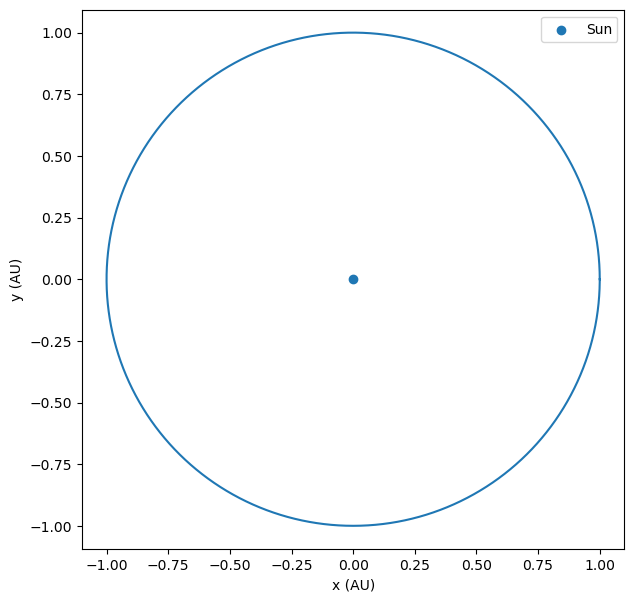

In [56]:
plt.figure(figsize=(7, 7))

plt.plot(
    history[:, 0] / physics.AU,
    history[:, 1] / physics.AU
)

plt.scatter(0, 0, label="Sun")

plt.xlabel("x (AU)")
plt.ylabel("y (AU)")
plt.axis("equal")
plt.legend()
plt.show()

Here, we've changed DT to 1000 seconds, because intgration with DT set to 1 is not particularly computationally efficiency. 

Orbital speed: 29788.8993205065
Initial state: [1.49600000e+11 0.00000000e+00 0.00000000e+00 0.00000000e+00
 2.97888993e+04 0.00000000e+00 0.00000000e+00]


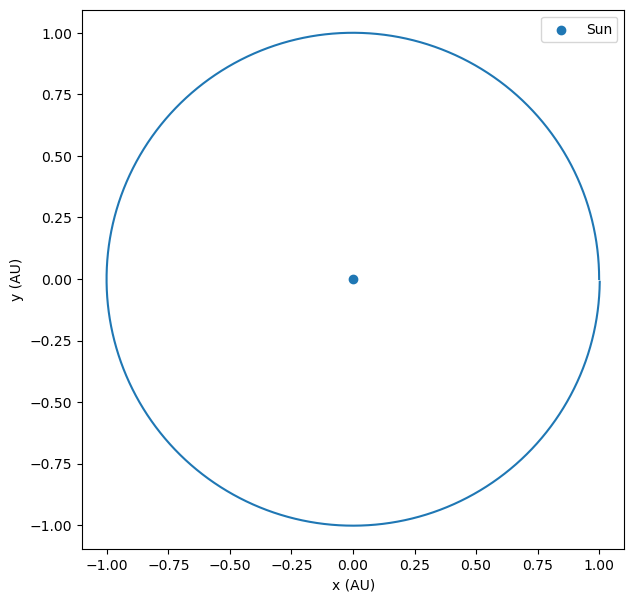

In [57]:
physics.DT = 1000

orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
year =  365.25 * 24 * 60 * 60

physics.position_vector = np.array([physics.AU, 0.0, 0.0])
physics.velocity_vector = np.array([0, orbit_speed, 0])

state = np.concatenate((physics.position_vector, physics.velocity_vector, [0.0]))

print("Orbital speed:", orbit_speed)
print("Initial state:", state)

history_1000 = physics.integrate_justg(year)

plt.figure(figsize=(7, 7))

plt.plot(
    history_1000[:, 0] / physics.AU,
    history_1000[:, 1] / physics.AU
)

plt.scatter(0, 0, label="Sun")

plt.xlabel("x (AU)")
plt.ylabel("y (AU)")
plt.axis("equal")
plt.legend()
plt.show()

To check the error from integration, we can verify in two ways: 
1. check the error in the first and last entry of the integration of the orbtial period,
2. Verify that total energy is constant, ie 
$$
E_{total} = \frac{1}{2}\mathbf{v}\cdot\mathbf{v} - \frac{GM_{\odot}}{r} \text{ is constant.} 
$$

In [58]:
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5
physics.DT = 1
physics.position_vector = np.array([physics.AU, 0.0, 0.0])
physics.velocity_vector = np.array([0, orbit_speed, 0])

state = np.concatenate((physics.position_vector, physics.velocity_vector, [0.0]))

history_orbital_period_dt1 = physics.integrate_justg(orbital_period)


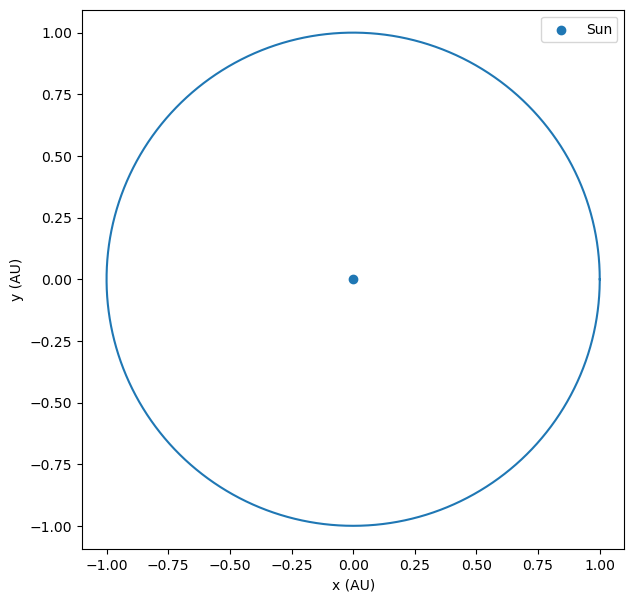

In [90]:
plt.figure(figsize=(7, 7))

plt.plot(
    history_orbital_period_dt1[:, 0] / physics.AU,
    history_orbital_period_dt1[:, 1] / physics.AU
)

plt.scatter(0, 0, label="Sun")

plt.xlabel("x (AU)")
plt.ylabel("y (AU)")
plt.axis("equal")
plt.legend()
plt.show()

In [30]:
# method 1 evaluation
initial_op1 = history_orbital_period_dt1[0]
final_op1 = history_orbital_period_dt1[-1]

pos_diff_op1 = np.linalg.norm(final_op1[:3] - initial_op1[:3])

vel_diff_op1 = np.linalg.norm(final_op1[3:-1] - initial_op1[3:-1]) 

print("position_difference relative to 1 AU: {}".format(pos_diff_op1/physics.AU))
print("velocity difference: {}".format(vel_diff_op1))

position_difference relative to 1 AU: 1.2005020263039918e-05
velocity difference: 0.3517411751605749


(array([-5.0e-07,  0.0e+00,  5.0e-07,  1.0e-06,  1.5e-06,  2.0e-06,
         2.5e-06,  3.0e-06]),
 [Text(0, -5e-07, '−0.5'),
  Text(0, 0.0, '0.0'),
  Text(0, 5e-07, '0.5'),
  Text(0, 1.0000000000000002e-06, '1.0'),
  Text(0, 1.5e-06, '1.5'),
  Text(0, 2e-06, '2.0'),
  Text(0, 2.5e-06, '2.5'),
  Text(0, 3e-06, '3.0')])

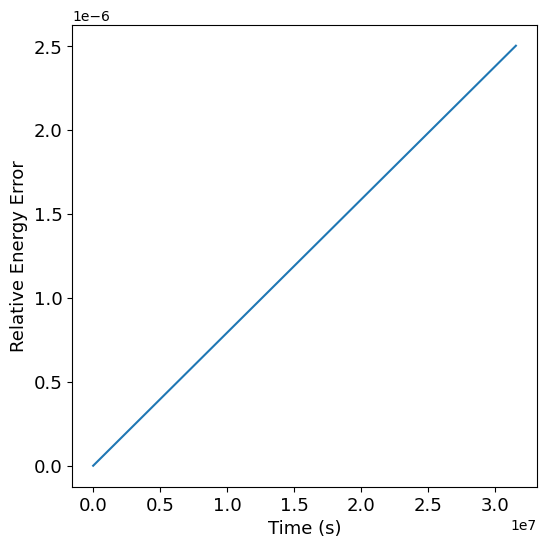

In [60]:
# method 2 evaluation 

position_op1 = history_orbital_period_dt1[:, :3]
velocity_op1 = history_orbital_period_dt1[:, 3:6]

magnitude_position_op1 = np.linalg.norm(position_op1, axis=1)
velocity_squared_op1 = np.sum(velocity_op1**2, axis=1)

total_energy = 0.5*velocity_squared_op1 - physics.GRAVITATIONAL * physics.SUN_MASS / magnitude_position_op1

plt.figure(figsize=(6,6))

plt.plot(
    history_orbital_period_dt1[:,-1],
    (total_energy - total_energy[0]) / np.linalg.norm(total_energy[0])
)

plt.xlabel("Time (s)", fontsize = 13)
plt.ylabel("Relative Energy Error", fontsize = 13)
plt.xticks(fontsize = 13)
plt.yticks(fontsize = 13) 

In [61]:
maximum_rel_error = (total_energy[-1] - total_energy[0])/np.linalg.norm(total_energy[0])
print("maximum relative energy error: {}".format(maximum_rel_error))

maximum relative energy error: 2.5022479062319065e-06


Try for dt = 10, 100, 1000

dt=10

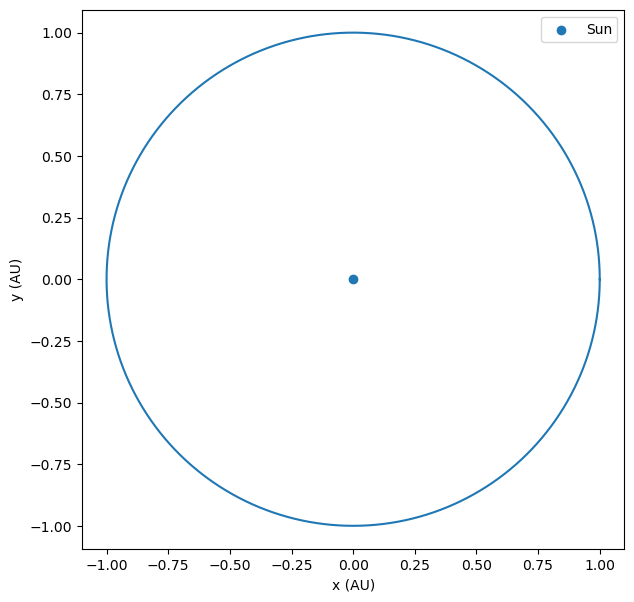

In [91]:
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5

physics.DT = 10

physics.position_vector = np.array([physics.AU, 0.0, 0.0])
physics.velocity_vector = np.array([0, orbit_speed, 0])

state = np.concatenate((physics.position_vector, physics.velocity_vector, [0.0]))

history_orbital_period_dt10 = physics.integrate_justg(orbital_period)

plt.figure(figsize=(7, 7))

plt.plot(
    history_orbital_period_dt10[:, 0] / physics.AU,
    history_orbital_period_dt10[:, 1] / physics.AU
)

plt.scatter(0, 0, label="Sun")

plt.xlabel("x (AU)")
plt.ylabel("y (AU)")
plt.axis("equal")
plt.legend()
plt.show()

In [63]:
# method 1 evaluation
initial_op10 = history_orbital_period_dt10[0]
final_op10 = history_orbital_period_dt10[-1]

pos_diff_op10 = np.linalg.norm(final_op10[:3] - initial_op10[:3])

vel_diff_op10 = np.linalg.norm(final_op10[3:-1] - initial_op10[3:-1]) 

print("position_difference relative to 1 AU: {}".format(pos_diff_op10/physics.AU))
print("velocity difference: {}".format(vel_diff_op10))

position_difference relative to 1 AU: 0.00012010113361839588
velocity difference: 3.5188918522861585


(array([-5.0e-06,  0.0e+00,  5.0e-06,  1.0e-05,  1.5e-05,  2.0e-05,
         2.5e-05,  3.0e-05]),
 [Text(0, -4.9999999999999996e-06, '−0.5'),
  Text(0, 0.0, '0.0'),
  Text(0, 4.9999999999999996e-06, '0.5'),
  Text(0, 9.999999999999999e-06, '1.0'),
  Text(0, 1.4999999999999999e-05, '1.5'),
  Text(0, 1.9999999999999998e-05, '2.0'),
  Text(0, 2.4999999999999998e-05, '2.5'),
  Text(0, 2.9999999999999997e-05, '3.0')])

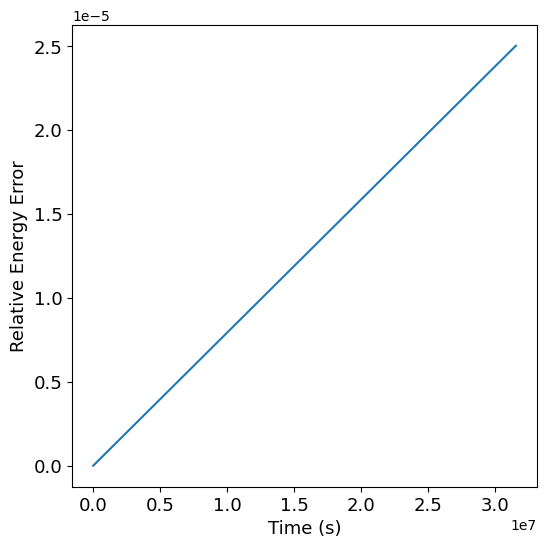

In [64]:
# method 2 evaluation 

position_op10 = history_orbital_period_dt10[:, :3]
velocity_op10 = history_orbital_period_dt10[:, 3:6]

magnitude_position_op10 = np.linalg.norm(position_op10, axis=1)
velocity_squared_op10 = np.sum(velocity_op10**2, axis=1)

total_energy_10 = 0.5*velocity_squared_op10 - physics.GRAVITATIONAL * physics.SUN_MASS / magnitude_position_op10

plt.figure(figsize=(6,6))

plt.plot(
    history_orbital_period_dt10[:,-1],
    (total_energy_10 - total_energy_10[0]) / np.linalg.norm(total_energy_10[0])
)

plt.xlabel("Time (s)", fontsize = 13)
plt.ylabel("Relative Energy Error", fontsize = 13)
plt.xticks(fontsize = 13)
plt.yticks(fontsize = 13) 

In [65]:
maximum_rel_error_10 = (total_energy_10[-1] - total_energy_10[0])/np.linalg.norm(total_energy_10[0])
print("maximum relative energy error: {}".format(maximum_rel_error_10))

maximum relative energy error: 2.5021366531288763e-05


dt=100

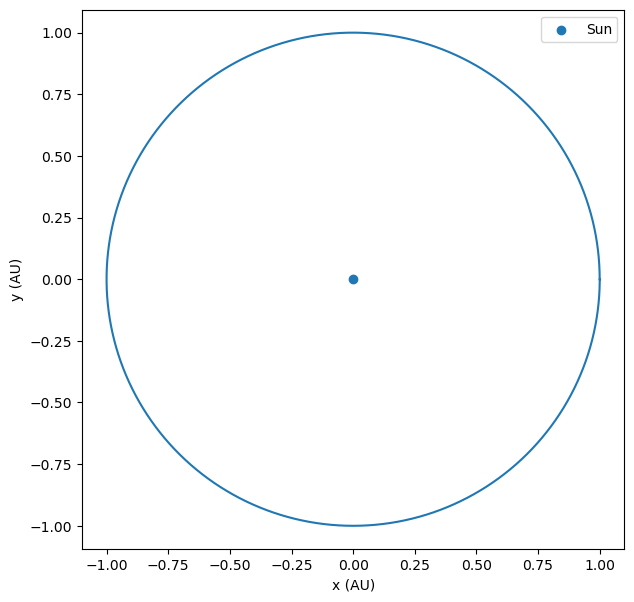

In [89]:
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5

physics.DT = 100

physics.position_vector = np.array([physics.AU, 0.0, 0.0])
physics.velocity_vector = np.array([0, orbit_speed, 0])

state = np.concatenate((physics.position_vector, physics.velocity_vector, [0.0]))

history_orbital_period_dt100 = physics.integrate_justg(orbital_period)

plt.figure(figsize=(7, 7))

plt.plot(
    history_orbital_period_dt100[:, 0] / physics.AU,
    history_orbital_period_dt100[:, 1] / physics.AU
)

plt.scatter(0, 0, label="Sun")

plt.xlabel("x (AU)")
plt.ylabel("y (AU)")
plt.axis("equal")
plt.legend()
plt.show()

In [67]:
# method 1 evaluation
initial_op100 = history_orbital_period_dt100[0]
final_op100 = history_orbital_period_dt100[-1]

pos_diff_op100 = np.linalg.norm(final_op100[:3] - initial_op100[:3])

vel_diff_op100 = np.linalg.norm(final_op100[3:-1] - initial_op100[3:-1]) 

print("position_difference relative to 1 AU: {}".format(pos_diff_op100/physics.AU))
print("velocity difference: {}".format(vel_diff_op100))

position_difference relative to 1 AU: 0.0012028115065300113
velocity difference: 35.23720355080271


(array([-5.0e-05,  0.0e+00,  5.0e-05,  1.0e-04,  1.5e-04,  2.0e-04,
         2.5e-04,  3.0e-04]),
 [Text(0, -5e-05, '−0.00005'),
  Text(0, 0.0, '0.00000'),
  Text(0, 5e-05, '0.00005'),
  Text(0, 0.00010000000000000002, '0.00010'),
  Text(0, 0.00015000000000000001, '0.00015'),
  Text(0, 0.0002, '0.00020'),
  Text(0, 0.00025, '0.00025'),
  Text(0, 0.0003, '0.00030')])

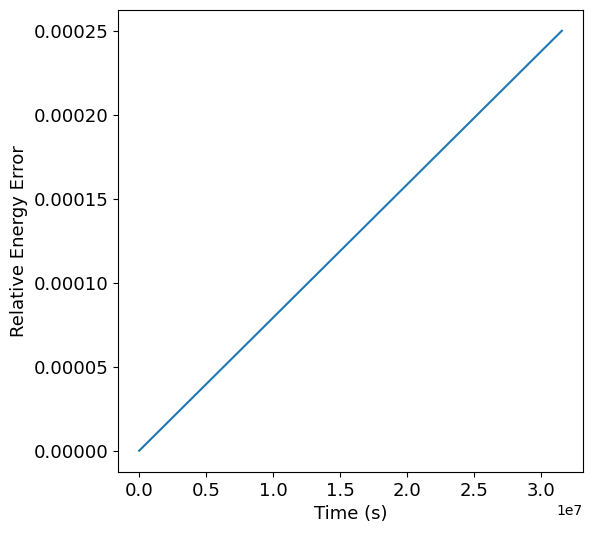

In [68]:
# method 2 evaluation 

position_op100 = history_orbital_period_dt100[:, :3]
velocity_op100 = history_orbital_period_dt100[:, 3:6]

magnitude_position_op100 = np.linalg.norm(position_op100, axis=1)
velocity_squared_op100 = np.sum(velocity_op100**2, axis=1)

total_energy_100 = 0.5*velocity_squared_op100 - physics.GRAVITATIONAL * physics.SUN_MASS / magnitude_position_op100

plt.figure(figsize=(6,6))

plt.plot(
    history_orbital_period_dt100[:,-1],
    (total_energy_100 - total_energy_100[0]) / np.linalg.norm(total_energy_100[0])
)

plt.xlabel("Time (s)", fontsize = 13)
plt.ylabel("Relative Energy Error", fontsize = 13)
plt.xticks(fontsize = 13)
plt.yticks(fontsize = 13) 

In [69]:
maximum_rel_error_100 = (total_energy_100[-1] - total_energy_100[0])/np.linalg.norm(total_energy_100[0])
print("maximum relative energy error: {}".format(maximum_rel_error_100))

maximum relative energy error: 0.0002501011096803597


dt = 1000

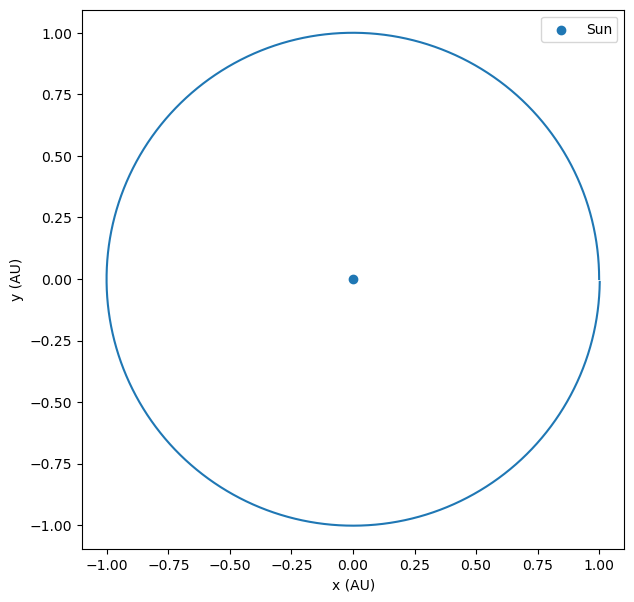

In [92]:
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5

physics.DT = 1000

physics.position_vector = np.array([physics.AU, 0.0, 0.0])
physics.velocity_vector = np.array([0, orbit_speed, 0])

state = np.concatenate((physics.position_vector, physics.velocity_vector, [0.0]))

history_orbital_period_dt1000 = physics.integrate_justg(orbital_period)

plt.figure(figsize=(7, 7))

plt.plot(
    history_orbital_period_dt1000[:, 0] / physics.AU,
    history_orbital_period_dt1000[:, 1] / physics.AU
)

plt.scatter(0, 0, label="Sun")

plt.xlabel("x (AU)")
plt.ylabel("y (AU)")
plt.axis("equal")
plt.legend()
plt.show()

In [71]:
# method 1 evaluation
initial_op1000 = history_orbital_period_dt1000[0]
final_op1000 = history_orbital_period_dt1000[-1]

pos_diff_op1000 = np.linalg.norm(final_op1000[:3] - initial_op1000[:3])

vel_diff_op1000 = np.linalg.norm(final_op1000[3:-1] - initial_op1000[3:-1]) 

print("position_difference relative to 1 AU: {}".format(pos_diff_op1000/physics.AU))
print("velocity difference: {}".format(vel_diff_op1000))

position_difference relative to 1 AU: 0.011874136338746719
velocity difference: 347.09565286128924


(array([-0.0005,  0.    ,  0.0005,  0.001 ,  0.0015,  0.002 ,  0.0025,
         0.003 ]),
 [Text(0, -0.0005, '−0.0005'),
  Text(0, 0.0, '0.0000'),
  Text(0, 0.0005, '0.0005'),
  Text(0, 0.001, '0.0010'),
  Text(0, 0.0015, '0.0015'),
  Text(0, 0.002, '0.0020'),
  Text(0, 0.0025, '0.0025'),
  Text(0, 0.003, '0.0030')])

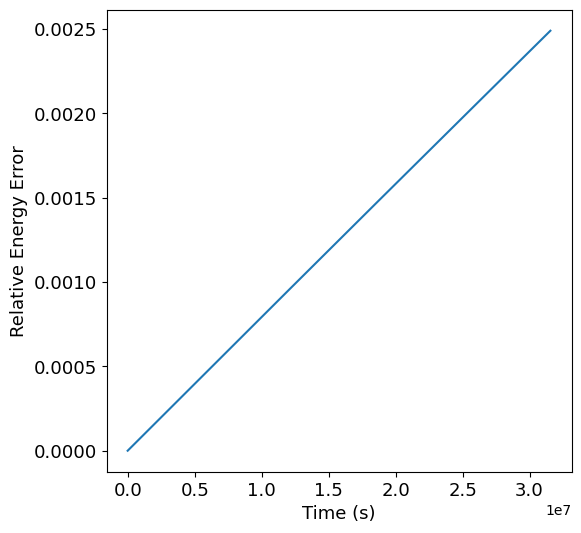

In [72]:
# method 2 evaluation 

position_op1000 = history_orbital_period_dt1000[:, :3]
velocity_op1000 = history_orbital_period_dt1000[:, 3:6]

magnitude_position_op1000 = np.linalg.norm(position_op1000, axis=1)
velocity_squared_op1000 = np.sum(velocity_op1000**2, axis=1)

total_energy_1000 = 0.5*velocity_squared_op1000 - physics.GRAVITATIONAL * physics.SUN_MASS / magnitude_position_op1000

plt.figure(figsize=(6,6))

plt.plot(
    history_orbital_period_dt1000[:,-1],
    (total_energy_1000 - total_energy_1000[0]) / np.linalg.norm(total_energy_1000[0])
)

plt.xlabel("Time (s)", fontsize = 13)
plt.ylabel("Relative Energy Error", fontsize = 13)
plt.xticks(fontsize = 13)
plt.yticks(fontsize = 13) 

In [73]:
maximum_rel_error_1000 = (total_energy_1000[-1] - total_energy_1000[0])/np.linalg.norm(total_energy_1000[0])
print("maximum relative energy error: {}".format(maximum_rel_error_1000))

maximum relative energy error: 0.0024898723544188304


## 2. Sails on at various constant angles 

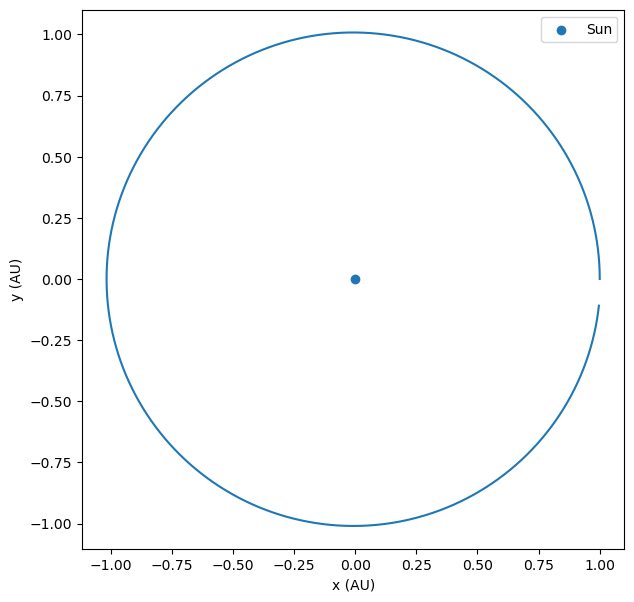

In [75]:
physics.a_angle = 0
physics.b_angle = 0
physics.DT = 1000

orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5

physics.position_vector = np.array([
    physics.AU, 0.0, 0.0
])
physics.velocity_vector = np.array([0, orbit_speed, 0])

#print(physics.a_due_to_gravity())
#print(physics.total_force_radiation() / physics.MASS)


history_orbital_period_dt1000_so_0 = physics.integrate(orbital_period)

plt.figure(figsize=(7, 7))

plt.plot(
    history_orbital_period_dt1000_so_0[:, 0] / physics.AU,
    history_orbital_period_dt1000_so_0[:, 1] / physics.AU
)

plt.scatter(0, 0, label="Sun")

plt.xlabel("x (AU)")
plt.ylabel("y (AU)")
plt.axis("equal")
plt.legend()
plt.show()

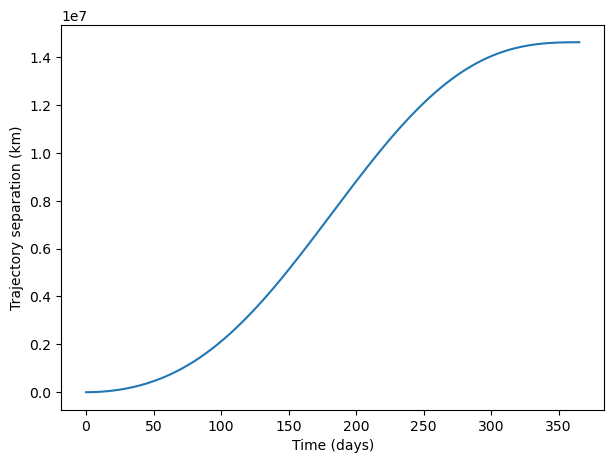

In [76]:
r_gravity = history_orbital_period_dt1000[:, :3]
r_sail = history_orbital_period_dt1000_so_0[:, :3]

separation = np.linalg.norm(
    r_sail - r_gravity,
    axis=1
)

time_days = history_orbital_period_dt1000[:, -1] / (24 * 3600)

plt.figure(figsize=(7, 5))

plt.plot(
    time_days,
    separation / 1000
)

plt.xlabel("Time (days)")
plt.ylabel("Trajectory separation (km)")
plt.show()

In [25]:
print(np.allclose(
    history_orbital_period_dt1000[:, -1],
    history_orbital_period_dt1000_so_0[:, -1]
))

print(history_orbital_period_dt1000.shape)
print(history_orbital_period_dt1000.shape)

True
(31556, 7)
(31556, 7)


Case when photons are 30 degrees to the normal of the sail

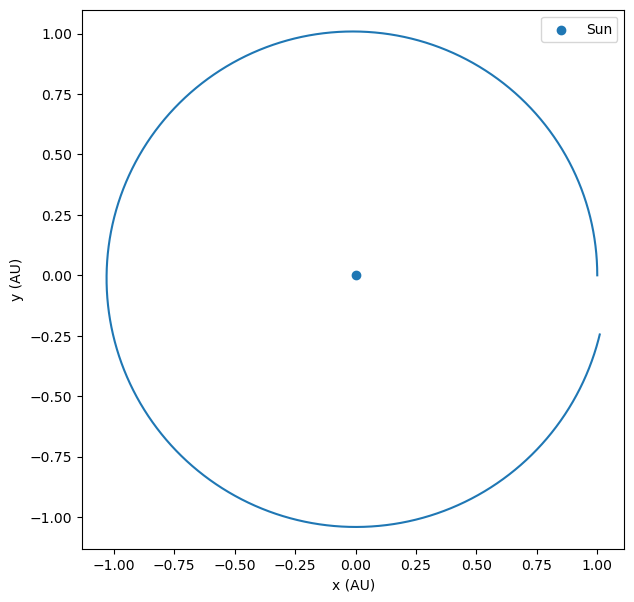

In [77]:
physics.a_angle = math.pi/6
physics.b_angle = 0
physics.DT = 1000

orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5

physics.position_vector = np.array([
    physics.AU, 0.0, 0.0
])
physics.velocity_vector = np.array([0, orbit_speed, 0])

#print(physics.a_due_to_gravity())
#print(physics.total_force_radiation() / physics.MASS)


history_orbital_period_dt1000_so_30 = physics.integrate(orbital_period)

plt.figure(figsize=(7, 7))

plt.plot(
    history_orbital_period_dt1000_so_30[:, 0] / physics.AU,
    history_orbital_period_dt1000_so_30[:, 1] / physics.AU
)

plt.scatter(0, 0, label="Sun")

plt.xlabel("x (AU)")
plt.ylabel("y (AU)")
plt.axis("equal")
plt.legend()
plt.show()

Photons 45 degrees to the normal of sail

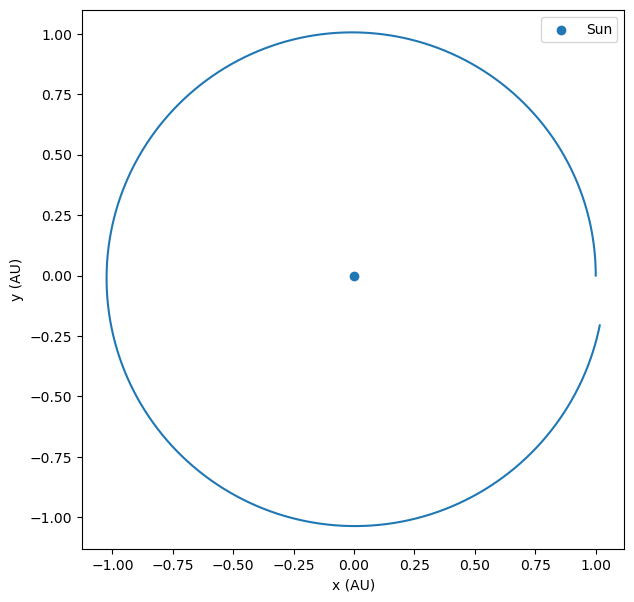

In [78]:
physics.a_angle = math.pi/4
physics.b_angle = 0
physics.DT = 1000

orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5

physics.position_vector = np.array([
    physics.AU, 0.0, 0.0
])
physics.velocity_vector = np.array([0, orbit_speed, 0])

#print(physics.a_due_to_gravity())
#print(physics.total_force_radiation() / physics.MASS)


history_orbital_period_dt1000_so_45 = physics.integrate(orbital_period)

plt.figure(figsize=(7, 7))

plt.plot(
    history_orbital_period_dt1000_so_45[:, 0] / physics.AU,
    history_orbital_period_dt1000_so_45[:, 1] / physics.AU
)

plt.scatter(0, 0, label="Sun")

plt.xlabel("x (AU)")
plt.ylabel("y (AU)")
plt.axis("equal")
plt.legend()
plt.show()

We check the case when photons from the sun are parallel to the sails. This is effecitvely the same as a space craft without sails, so we should obtain the same result without sails. We confirm this:

Photons with angle 60 degrees to the normal of the sail

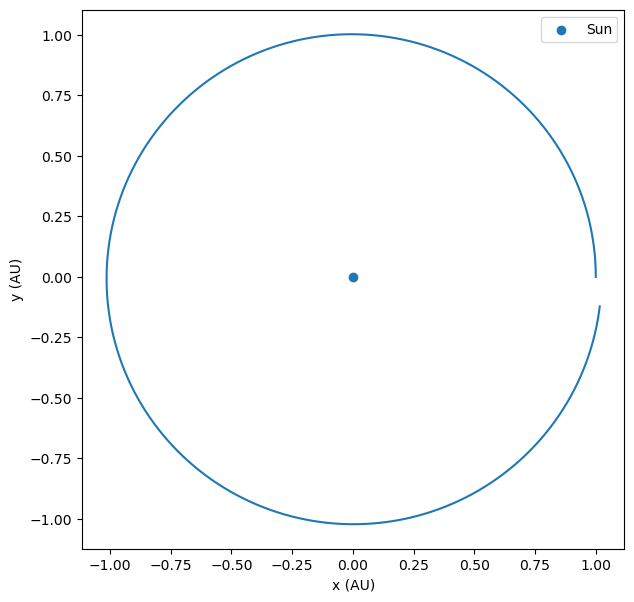

In [79]:
physics.a_angle = math.pi/3
physics.b_angle = 0
physics.DT = 1000

orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5

physics.position_vector = np.array([
    physics.AU, 0.0, 0.0
])
physics.velocity_vector = np.array([0, orbit_speed, 0])

#print(physics.a_due_to_gravity())
#print(physics.total_force_radiation() / physics.MASS)


history_orbital_period_dt1000_so_60 = physics.integrate(orbital_period)

plt.figure(figsize=(7, 7))

plt.plot(
    history_orbital_period_dt1000_so_60[:, 0] / physics.AU,
    history_orbital_period_dt1000_so_60[:, 1] / physics.AU
)

plt.scatter(0, 0, label="Sun")

plt.xlabel("x (AU)")
plt.ylabel("y (AU)")
plt.axis("equal")
plt.legend()
plt.show()

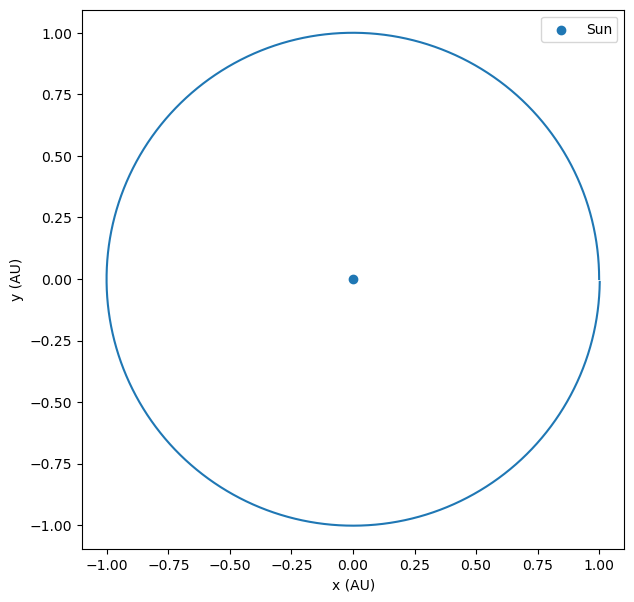

In [80]:
#verify that at 

physics.a_angle = math.pi/2
physics.b_angle = 0
physics.DT = 1000

orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5

physics.position_vector = np.array([
    physics.AU, 0.0, 0.0
])
physics.velocity_vector = np.array([0, orbit_speed, 0])

#print(physics.a_due_to_gravity())
#print(physics.total_force_radiation() / physics.MASS)


history_orbital_period_dt1000_so_90 = physics.integrate(orbital_period)

plt.figure(figsize=(7, 7))

plt.plot(
    history_orbital_period_dt1000_so_90[:, 0] / physics.AU,
    history_orbital_period_dt1000_so_90[:, 1] / physics.AU
)

plt.scatter(0, 0, label="Sun")

plt.xlabel("x (AU)")
plt.ylabel("y (AU)")
plt.axis("equal")
plt.legend()
plt.show()

[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 ...
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
(31556, 3)


Text(0, 0.5, 'Difference (m)')

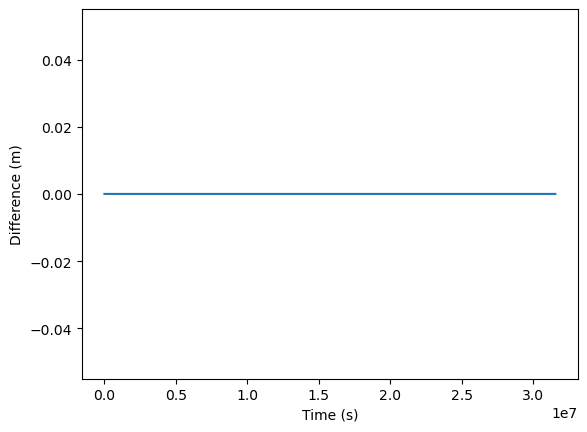

In [81]:
difference = history_orbital_period_dt1000[:,0:3] - history_orbital_period_dt1000_so_90[:,0:3]
print(difference)
time = history_orbital_period_dt1000[:,-1]

print(difference.shape)

magnitude_difference = np.linalg.norm(difference, axis=1)

plt.plot(time, magnitude_difference)
plt.xlabel("Time (s)")
plt.ylabel("Difference (m)")

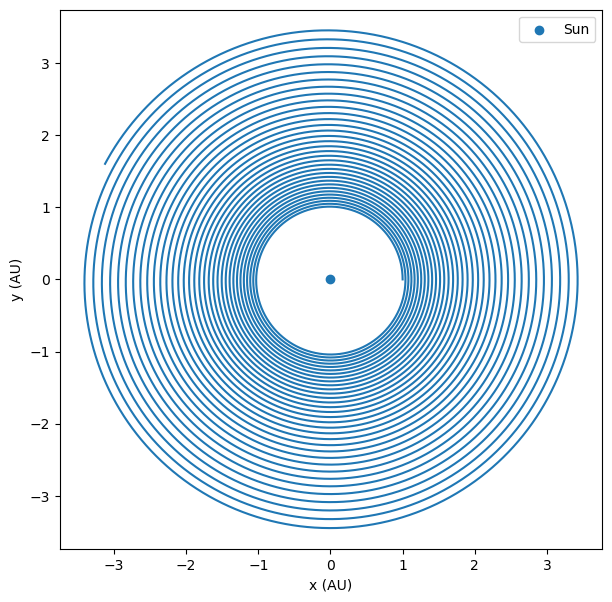

In [82]:
physics.a_angle = math.pi/6
physics.b_angle = 0
physics.DT = 1000

orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5

physics.position_vector = np.array([
    physics.AU, 0.0, 0.0
])
physics.velocity_vector = np.array([0, orbit_speed, 0])

#print(physics.a_due_to_gravity())
#print(physics.total_force_radiation() / physics.MASS)


history_orbital_period_dt1000_so_30 = physics.integrate(100*orbital_period)

plt.figure(figsize=(7, 7))

plt.plot(
    history_orbital_period_dt1000_so_30[:, 0] / physics.AU,
    history_orbital_period_dt1000_so_30[:, 1] / physics.AU
)

plt.scatter(0, 0, label="Sun")

plt.xlabel("x (AU)")
plt.ylabel("y (AU)")
plt.axis("equal")
plt.legend()
plt.show()

(3155420,)


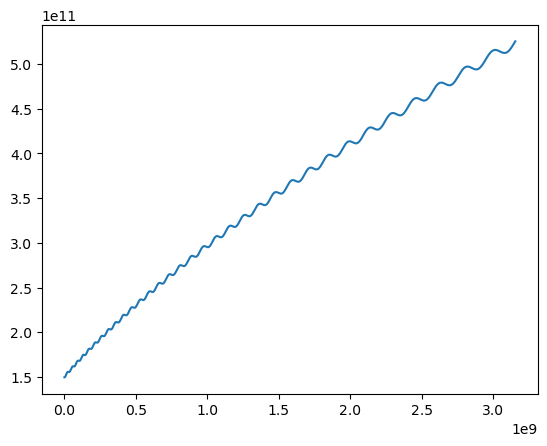

In [83]:
distance_30_10 = np.linalg.norm(history_orbital_period_dt1000_so_30[:,0:3], axis=1)
time = history_orbital_period_dt1000_so_30[:,-1]
print(distance_30_10.shape)
plt.plot(time, distance_30_10)
plt.show()


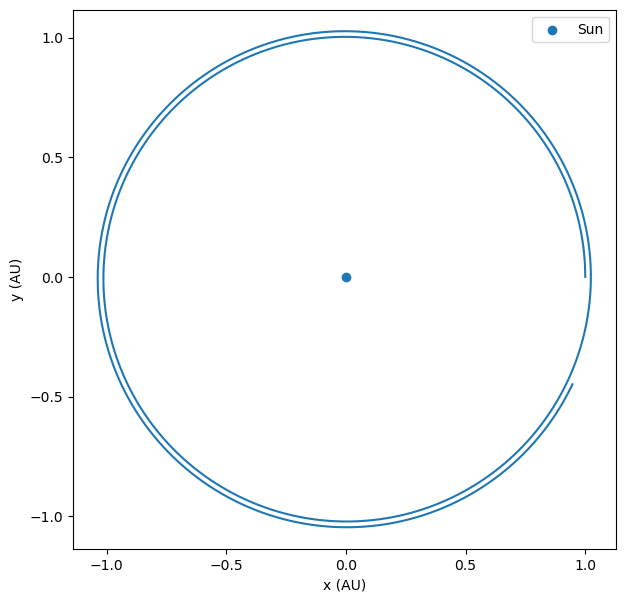

In [84]:
physics.a_angle = math.pi/3
physics.b_angle = 0
physics.DT = 1000

orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5

physics.position_vector = np.array([
    physics.AU, 0.0, 0.0
])
physics.velocity_vector = np.array([0, orbit_speed, 0])
#print(physics.a_due_to_gravity())
#print(physics.total_force_radiation() / physics.MASS)


history_orbital_period_dt1000_so_60 = physics.integrate(2*orbital_period)

plt.figure(figsize=(7, 7))

plt.plot(
    history_orbital_period_dt1000_so_60[:, 0] / physics.AU,
    history_orbital_period_dt1000_so_60[:, 1] / physics.AU
)

plt.scatter(0, 0, label="Sun")

plt.xlabel("x (AU)")
plt.ylabel("y (AU)")
plt.axis("equal")
plt.legend()
plt.show()

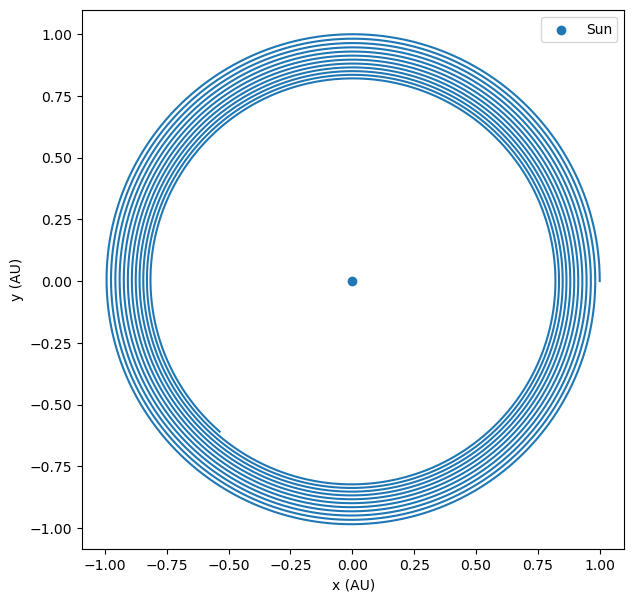

In [85]:
physics.a_angle = -math.pi/3
physics.b_angle = 0
physics.DT = 1000

orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5

physics.position_vector = np.array([
    physics.AU, 0.0, 0.0
])
physics.velocity_vector = np.array([0, orbit_speed, 0])

#print(physics.a_due_to_gravity())
#print(physics.total_force_radiation() / physics.MASS)


history_orbital_period_dt1000_so_60 = physics.integrate(10*orbital_period)

plt.figure(figsize=(7, 7))

plt.plot(
    history_orbital_period_dt1000_so_60[:, 0] / physics.AU,
    history_orbital_period_dt1000_so_60[:, 1] / physics.AU
)

plt.scatter(0, 0, label="Sun")

plt.xlabel("x (AU)")
plt.ylabel("y (AU)")
plt.axis("equal")
plt.legend()
plt.show()

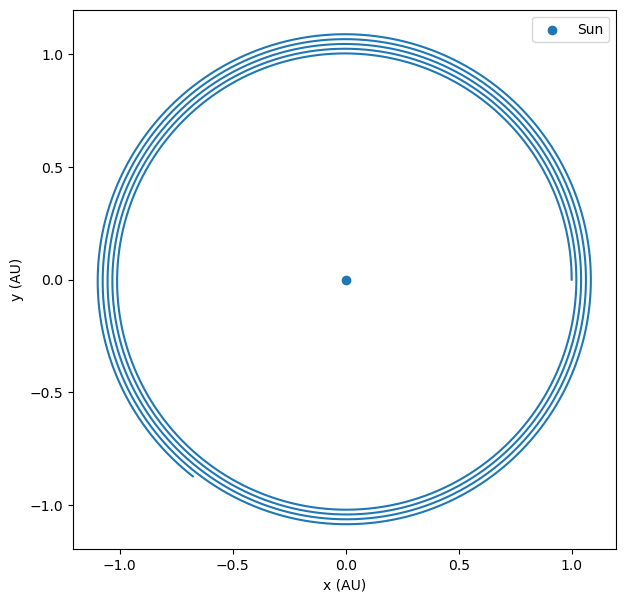

In [86]:
physics.a_angle = math.pi/3
physics.b_angle = math.pi/6
physics.DT = 1000

orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5

physics.position_vector = np.array([
    physics.AU, 0.0, 0.0
])
physics.velocity_vector = np.array([0, orbit_speed, 0])

#print(physics.a_due_to_gravity())
#print(physics.total_force_radiation() / physics.MASS)


history_orbital_period_dt1000_so_60 = physics.integrate(5*orbital_period)

plt.figure(figsize=(7, 7))

plt.plot(
    history_orbital_period_dt1000_so_60[:, 0] / physics.AU,
    history_orbital_period_dt1000_so_60[:, 1] / physics.AU
)

plt.scatter(0, 0, label="Sun")

plt.xlabel("x (AU)")
plt.ylabel("y (AU)")
plt.axis("equal")
plt.legend()
plt.show()

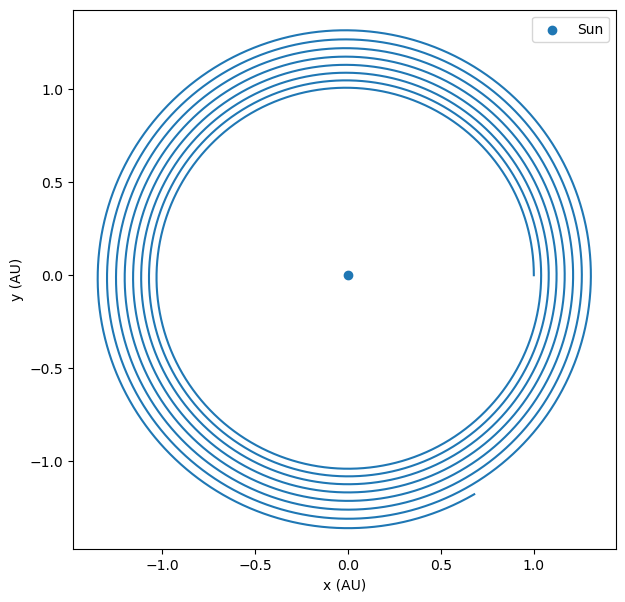

In [87]:
physics.a_angle = math.pi/6
physics.b_angle = 0
physics.DT = 1000

orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5
year = 365.25*24*3600

physics.position_vector = np.array([
    physics.AU, 0.0, 0.0
])
physics.velocity_vector = np.array([0, orbit_speed, 0])

#print(physics.a_due_to_gravity())
#print(physics.total_force_radiation() / physics.MASS)


history_orbital_period_dt1000_so_10 = physics.integrate(10*orbital_period)

plt.figure(figsize=(7, 7))

plt.plot(
    history_orbital_period_dt1000_so_10[:, 0] / physics.AU,
    history_orbital_period_dt1000_so_10[:, 1] / physics.AU
)

plt.scatter(0, 0, label="Sun")

plt.xlabel("x (AU)")
plt.ylabel("y (AU)")
plt.axis("equal")
plt.legend()
plt.show()

In [93]:
"""r = np.linalg.norm(history_orbital_period_dt1000_so_10[:, :3], axis=1)
v = np.linalg.norm(history_orbital_period_dt1000_so_10[:, 3:6], axis=1)
time = history_orbital_period_dt1000_so_10[:,-1]

epsilon = 0.5 * v**2 - physics.GRAVITATIONAL * physics.SUN_MASS / r

plt.plot(time/ (365.25*24*3600), epsilon)
plt.axhline(0, linestyle="--")
plt.xlabel("Time (years)")
plt.ylabel("Specific orbital energy (J/kg)")"""

'r = np.linalg.norm(history_orbital_period_dt1000_so_10[:, :3], axis=1)\nv = np.linalg.norm(history_orbital_period_dt1000_so_10[:, 3:6], axis=1)\ntime = history_orbital_period_dt1000_so_10[:,-1]\n\nepsilon = 0.5 * v**2 - physics.GRAVITATIONAL * physics.SUN_MASS / r\n\nplt.plot(time/ (365.25*24*3600), epsilon)\nplt.axhline(0, linestyle="--")\nplt.xlabel("Time (years)")\nplt.ylabel("Specific orbital energy (J/kg)")'

## Reaching Mars' orbital radius

In [14]:
#first partition the allowed orientations 

physics.a_angle = 0
physics.b_angle = 0
physics.DT = 1000
physics.SAIL_AREA = 2500
physics.MASS = 25

#initial conditions: Earth orbit
orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5

physics.position_vector = np.array([
    physics.AU, 0.0, 0.0])
physics.velocity_vector = np.array([0, orbit_speed, 0])

mars_orbit_radius = 1.524*physics.AU

deg_to_rad = math.pi/180

alpha_partition = [10*n for n in range(0, 19)]
beta_partition = [10*n for n in range(0, 37)]

In [8]:
isail_to_mars_trial = physics.integrate_to_orbit(mars_orbit_radius, 5*orbital_period)

In [10]:
print(isail_to_mars_trial[-1])
last_entry = isail_to_mars_trial[0][-1][:3]

print(last_entry)
print(np.linalg.norm(last_entry)/physics.AU)

print(physics.SAIL_AREA)

False
[-2.04434875e+11 -3.94263407e+10  0.00000000e+00]
1.3917243060091777
2500


In [ ]:
to_mars_trial = physics.integrate_to_orbit(mars_orbit_radius, 50*orbital_period)

In [124]:
print(to_mars_trial[-1])
last_entry = to_mars_trial[0][-1][:3]

print(last_entry)
print(np.linalg.norm(last_entry)/physics.AU)

False
[-1.89469795e+11 -7.84118775e+10  0.00000000e+00]
1.3706831697559443


In [15]:
integration_all = []

for ai in alpha_partition:
    for bi in beta_partition:
        orientation = [ai,bi] #IN DEGREES
        physics.a_angle = ai * deg_to_rad
        physics.b_angle = bi * deg_to_rad

        orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
        orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5

        physics.position_vector = np.array(
            [physics.AU, 0.0, 0.0]
        )
        physics.velocity_vector = np.array([0, orbit_speed, 0])

        integration = physics.integrate_to_orbit(mars_orbit_radius, 5*orbital_period)
        integration_all.append([integration, orientation])

        print(orientation)

[0, 0]
[0, 10]
[0, 20]
[0, 30]
[0, 40]
[0, 50]
[0, 60]
[0, 70]
[0, 80]
[0, 90]
[0, 100]
[0, 110]
[0, 120]
[0, 130]
[0, 140]
[0, 150]
[0, 160]
[0, 170]
[0, 180]
[0, 190]
[0, 200]
[0, 210]
[0, 220]
[0, 230]
[0, 240]
[0, 250]
[0, 260]
[0, 270]
[0, 280]
[0, 290]
[0, 300]
[0, 310]
[0, 320]
[0, 330]
[0, 340]
[0, 350]
[0, 360]
[10, 0]
[10, 10]
[10, 20]
[10, 30]
[10, 40]
[10, 50]
[10, 60]
[10, 70]
[10, 80]
[10, 90]
[10, 100]
[10, 110]
[10, 120]
[10, 130]
[10, 140]
[10, 150]
[10, 160]
[10, 170]
[10, 180]
[10, 190]
[10, 200]
[10, 210]
[10, 220]
[10, 230]
[10, 240]
[10, 250]
[10, 260]
[10, 270]
[10, 280]
[10, 290]
[10, 300]
[10, 310]
[10, 320]
[10, 330]
[10, 340]
[10, 350]
[10, 360]
[20, 0]
[20, 10]
[20, 20]
[20, 30]
[20, 40]
[20, 50]
[20, 60]
[20, 70]
[20, 80]
[20, 90]
[20, 100]
[20, 110]
[20, 120]
[20, 130]
[20, 140]
[20, 150]
[20, 160]
[20, 170]
[20, 180]
[20, 190]
[20, 200]
[20, 210]
[20, 220]
[20, 230]
[20, 240]
[20, 250]
[20, 260]
[20, 270]
[20, 280]
[20, 290]
[20, 300]
[20, 310]
[20, 320]


In [64]:
import pickle

with open("integration_all.pkl", "wb") as f:
    pickle.dump(integration_all, f, protocol=pickle.HIGHEST_PROTOCOL)

"""
with open("integration_all.pkl", "rb") as f:
    integration_all = pickle.load(f)
"""

'\nwith open("integration_all.pkl", "rb") as f:\n    integration_all = pickle.load(f)\n'

In [71]:
import os
print(os.path.abspath("integration_all.pkl"))

/Users/peytaguo/PHYS2201/Solar Sail Computational Project/integration_all.pkl


In [79]:
successful_orientation = []

false_count = 0
true_count = 0

for orientation in integration_all:
    if orientation[-2][-1] == True:
        true_count += 1
        last_position = np.linalg.norm(orientation[0][0][-1][:3])
        last_time = orientation[0][0][-1][-1]/(3600*24)
        success = [orientation[-1][0], orientation[-1][1], last_time, last_position]
        successful_orientation.append( success )
    else:
        false_count += 1

In [81]:
successful_orientation = np.array(successful_orientation)

In [264]:
orientations_a = successful_orientation[:, 0]
orientations_b = np.array(successful_orientation[:, 1])

times = successful_orientation[:, 2]

print(orientations_b)
  

[  0.  10.  20.  30.  40.  50.  60.  70.  80. 140. 150. 160. 170.   0.
  10.  20.  30.  40. 100. 110. 120. 130. 140. 150. 160. 170.   0.   0.
  10.  20.  30.  40.  50.  60.  70.  80. 120. 130. 140. 150. 160. 170.
   0.  10.  20.  30.  40.  50.  60. 100. 110. 120. 130. 140. 150. 160.
 170.   0.   0.  10.  20.  30.  40.  50.  60.  70.  80. 110. 120. 130.
 140. 150. 160. 170.   0.  10.  20.  30.  40.  50.  60.  70. 100. 110.
 120. 130. 140. 150. 160. 170.   0.   0.  10.  20.  30.  40.  50.  60.
  70.  80. 110. 120. 130. 140. 150. 160. 170.   0.  10.  20.  30.  40.
  50.  60.  70. 100. 110. 120. 130. 140. 150. 160. 170.   0.   0.  10.
  20.  30.  40.  50.  60.  70.  80. 120. 130. 140. 150. 160. 170.   0.
  10.  20.  30.  40.  50.  60. 100. 110. 120. 130. 140. 150. 160. 170.
   0.   0.  10.  20.  30.  40.  50.  60.  70. 130. 140. 150. 160. 170.
   0.  10.  20.  30.  40.  50. 110. 120. 130. 140. 150. 160. 170.   0.
   0.  10.  20.  30.  40.  50. 130. 140. 150. 160. 170.   0.]


Text(0, 0.5, '$\\beta$ (degrees)')

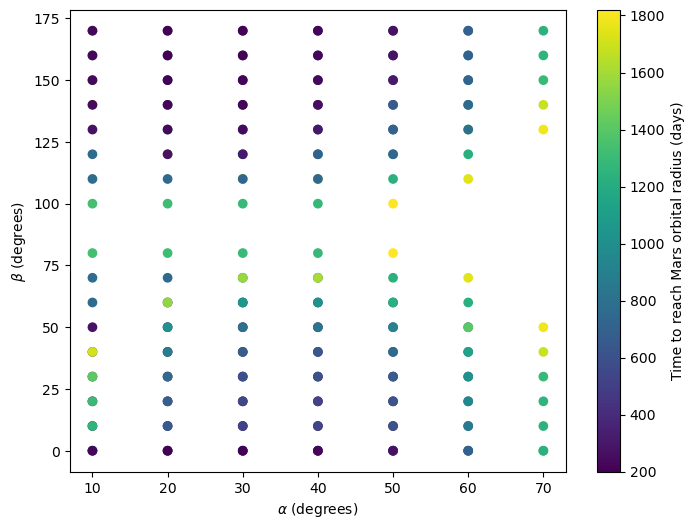

In [263]:
plt.figure(figsize=(8, 6))

plt.scatter(
    orientations_a,
    orientations_b,
    c=times
)

plt.colorbar(label="Time to reach Mars orbital radius (days)")
plt.xlabel(r"$\alpha$ (degrees)")
plt.ylabel(r"$\beta$ (degrees)")

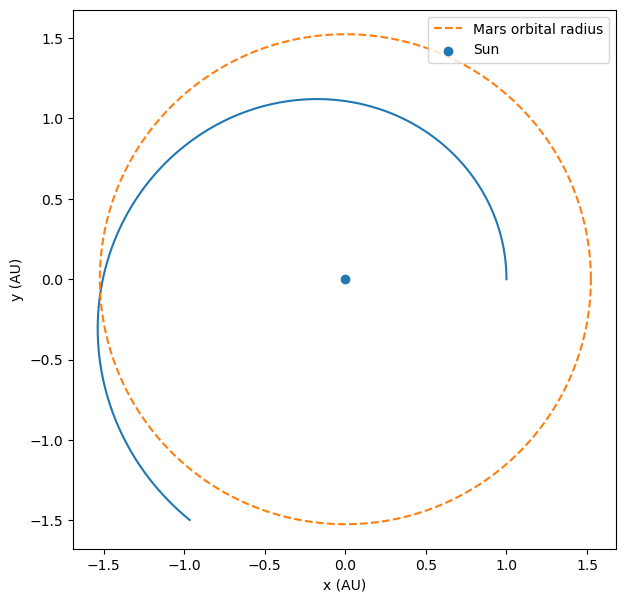

In [107]:
theta = np.linspace(0, 2*np.pi, 500)

mars_radius = 1.524  # AU

mars_x = mars_radius * np.cos(theta)
mars_y = mars_radius * np.sin(theta)



physics.a_angle = math.pi/4
physics.b_angle = 0
physics.DT = 1000

orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5

physics.position_vector = np.array([
    physics.AU, 0.0, 0.0
])
physics.velocity_vector = np.array([0, orbit_speed, 0])

#print(physics.a_due_to_gravity())
#print(physics.total_force_radiation() / physics.MASS)


history_orbital_period_trial = physics.integrate(orbital_period)

plt.figure(figsize=(7, 7))

plt.plot(
    history_orbital_period_trial[:, 0] / physics.AU,
    history_orbital_period_trial[:, 1] / physics.AU
)

plt.plot(mars_x, mars_y, "--", label="Mars orbital radius")

plt.scatter(0, 0, label="Sun")

plt.xlabel("x (AU)")
plt.ylabel("y (AU)")
plt.axis("equal")
plt.legend(loc="upper right")
plt.show()

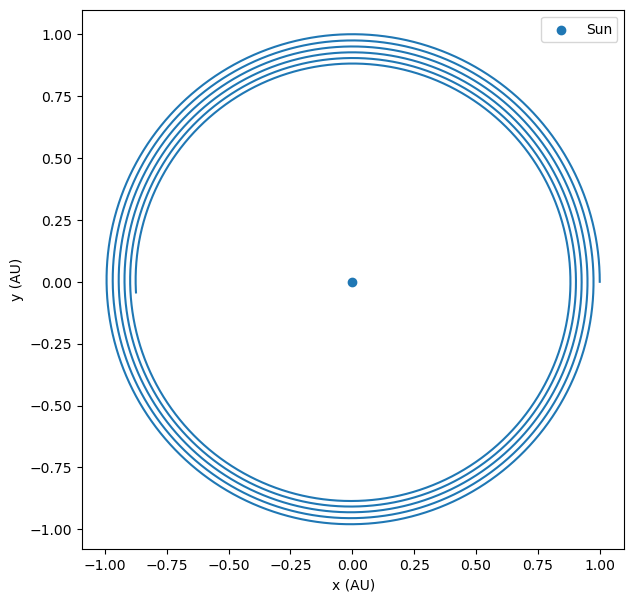

In [148]:
theta = np.linspace(0, 2*np.pi, 500)

mars_radius = 1.524  # AU

mars_x = mars_radius * np.cos(theta)
mars_y = mars_radius * np.sin(theta)



physics.a_angle = math.pi/4
physics.b_angle = math.pi
physics.DT = 1000

orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5

physics.position_vector = np.array([
    physics.AU, 0.0, 0.0
])
physics.velocity_vector = np.array([0, orbit_speed, 0])

#print(physics.a_due_to_gravity())
#print(physics.total_force_radiation() / physics.MASS)


history_orbital_period_trial = physics.integrate(5*orbital_period)

plt.figure(figsize=(7, 7))

plt.plot(
    history_orbital_period_trial[:, 0] / physics.AU,
    history_orbital_period_trial[:, 1] / physics.AU
)

#plt.plot(mars_x, mars_y, "--", label="Mars orbital radius")

plt.scatter(0, 0, label="Sun")

plt.xlabel("x (AU)")
plt.ylabel("y (AU)")
plt.axis("equal")
plt.legend(loc="upper right")
plt.show()

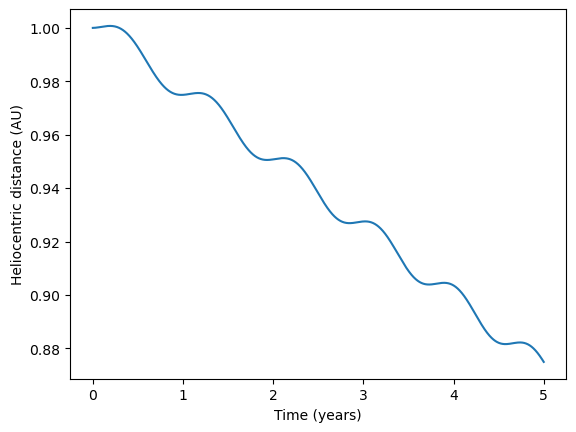

In [143]:
r = np.linalg.norm(history_orbital_period_trial[:, :3], axis=1)

time = history_orbital_period_trial[:, -1]

plt.plot(time / (365.25*24*3600), r / physics.AU)
plt.xlabel("Time (years)")
plt.ylabel("Heliocentric distance (AU)")
plt.show()

In [136]:
r = np.linalg.norm(history_orbital_period_trial[:, :3], axis=1)

print("Minimum r (AU):", np.min(r) / physics.AU)

Minimum r (AU): 0.8749190616037361


In [139]:
a_sail = physics.total_force_radiation() / physics.MASS

print("a_R =", np.dot(a_sail, physics.sun_unit_vector()))
print("a_T =", np.dot(a_sail, physics.T_unit_vector()))
print("a_N =", np.dot(a_sail, physics.N_unit_vector()))

a_R = 2.0967983771995145e-05
a_T = -1.7193746693036012e-05
a_N = 2.105626685297694e-21


In [147]:
physics.position_vector = np.array([physics.AU, 0.0, 0.0])
physics.velocity_vector = np.array([0.0, orbit_speed, 0.0])

physics.a_angle = np.pi/4
physics.b_angle = np.pi

print("mass =", physics.MASS)
print("area =", physics.SAIL_AREA)
print("reflectivity =", physics.R)

a_sail = physics.total_force_radiation() / physics.MASS

print("a_R =", np.dot(a_sail, physics.sun_unit_vector()))
print("a_T =", np.dot(a_sail, physics.T_unit_vector()))
print("a_N =", np.dot(a_sail, physics.N_unit_vector()))
print("|a_sail| =", np.linalg.norm(a_sail))

mass = 16
area = 80
reflectivity = 0.82
a_R = 1.6050642761581607e-05
a_T = -1.3161527064496915e-05
a_N = 1.6118221991427405e-21
|a_sail| = 2.0756900725527326e-05


In [155]:
physics.a_angle = math.pi/4
physics.b_angle = math.pi
physics.DT = 1000

orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5

physics.position_vector = np.array([
    physics.AU, 0.0, 0.0
])
physics.velocity_vector = np.array([0, orbit_speed, 0])


history_orbital_period_trial = physics.integrate_without_history(mars_orbit_radius, 5*orbital_period)

In [156]:
print("Minimum r (AU):", np.min(r) / physics.AU)

Minimum r (AU): 0.8749190616037361


The scatter plot showed some suspicious results. Further investigations of some of these orientations showed that the space craft managed to get very close to the sun, resulting in some erroneous simulaiton data. A new integrator was created to stop the integration if the space craft crashes into the Sun. 

In [158]:
#first partition the allowed orientations 

physics.a_angle = 0
physics.b_angle = 0

physics.DT = 1000
physics.SAIL_AREA = 2500
physics.MASS = 25

#initial conditions: Earth orbit
orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5

physics.position_vector = np.array([
    physics.AU, 0.0, 0.0])
physics.velocity_vector = np.array([0, orbit_speed, 0])

mars_orbit_radius = 1.524*physics.AU

deg_to_rad = math.pi/180

alpha_partition = [10*n for n in range(0, 19)]
beta_partition = [10*n for n in range(0, 37)]

In [160]:
integration_all_v2 = []

for ai in alpha_partition:
    for bi in beta_partition:
        orientation = [ai,bi] #IN DEGREES
        physics.a_angle = ai * deg_to_rad
        physics.b_angle = bi * deg_to_rad

        orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
        orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5

        physics.position_vector = np.array(
            [physics.AU, 0.0, 0.0]
        )
        physics.velocity_vector = np.array([0, orbit_speed, 0])

        integration = physics.integrate_without_history(mars_orbit_radius, 3*orbital_period)
        integration_all.append([integration, orientation])

        print(orientation)

[0, 0]
[0, 10]
[0, 20]
[0, 30]
[0, 40]
[0, 50]
[0, 60]
[0, 70]
[0, 80]
[0, 90]
[0, 100]
[0, 110]
[0, 120]
[0, 130]
[0, 140]
[0, 150]
[0, 160]
[0, 170]
[0, 180]
[0, 190]
[0, 200]
[0, 210]
[0, 220]
[0, 230]
[0, 240]
[0, 250]
[0, 260]
[0, 270]
[0, 280]
[0, 290]
[0, 300]
[0, 310]
[0, 320]
[0, 330]
[0, 340]
[0, 350]
[0, 360]
[10, 0]
[10, 10]
[10, 20]
[10, 30]
[10, 40]
[10, 50]
[10, 60]
[10, 70]
[10, 80]
[10, 90]
[10, 100]
[10, 110]
[10, 120]
[10, 130]
[10, 140]
[10, 150]
[10, 160]
[10, 170]
[10, 180]
[10, 190]
[10, 200]
[10, 210]
[10, 220]
[10, 230]
[10, 240]
[10, 250]
[10, 260]
[10, 270]
[10, 280]
[10, 290]
[10, 300]
[10, 310]
[10, 320]
[10, 330]
[10, 340]
[10, 350]
[10, 360]
[20, 0]
[20, 10]
[20, 20]
[20, 30]
[20, 40]
[20, 50]
[20, 60]
[20, 70]
[20, 80]
[20, 90]
[20, 100]
[20, 110]
[20, 120]
[20, 130]
[20, 140]
[20, 150]
[20, 160]
[20, 170]
[20, 180]
[20, 190]
[20, 200]
[20, 210]
[20, 220]
[20, 230]
[20, 240]
[20, 250]
[20, 260]
[20, 270]
[20, 280]
[20, 290]
[20, 300]
[20, 310]
[20, 320]


In [197]:
integration_all_v2 = integration_all[18*36+55:]

import pickle

with open("integration_all_v2.pkl", "wb") as f:
    pickle.dump(integration_all_v2, f, protocol=pickle.HIGHEST_PROTOCOL)

"""
with open("integration_all_v2.pkl_", "rb") as f:
    integration_all = pickle.load(f)
"""

'\nwith open("integration_all_v2.pkl_", "rb") as f:\n    integration_all = pickle.load(f)\n'

In [210]:
print(integration_all_v2)

[[(array([7.61715694e+10, 1.43105776e+11, 0.00000000e+00]), 94663000.0, np.False_), [0, 0]], [(array([7.61715694e+10, 1.43105776e+11, 0.00000000e+00]), 94663000.0, np.False_), [0, 0]], [(array([7.61715694e+10, 1.43105776e+11, 0.00000000e+00]), 94663000.0, np.False_), [0, 10]], [(array([7.61715694e+10, 1.43105776e+11, 0.00000000e+00]), 94663000.0, np.False_), [0, 20]], [(array([7.61715694e+10, 1.43105776e+11, 0.00000000e+00]), 94663000.0, np.False_), [0, 30]], [(array([7.61715694e+10, 1.43105776e+11, 0.00000000e+00]), 94663000.0, np.False_), [0, 40]], [(array([7.61715694e+10, 1.43105776e+11, 0.00000000e+00]), 94663000.0, np.False_), [0, 50]], [(array([7.61715694e+10, 1.43105776e+11, 0.00000000e+00]), 94663000.0, np.False_), [0, 60]], [(array([7.61715694e+10, 1.43105776e+11, 0.00000000e+00]), 94663000.0, np.False_), [0, 70]], [(array([7.61715694e+10, 1.43105776e+11, 0.00000000e+00]), 94663000.0, np.False_), [0, 80]], [(array([7.61715694e+10, 1.43105776e+11, 0.00000000e+00]), 94663000.0, 

In [278]:
false_count = 0
true_count = 0

successful = []

for o in integration_all_v2:
    if o[0][-1] == True:
        time = o[0][-2]/(3600*24)
        a = o[-1][0]
        b = o[-1][1]
        successful.append([a,b,time])

In [279]:
successful = np.array(successful)


orientations_a = successful[:,0]
orientations_b = successful[:,1]
times = successful[:,-1]


Text(0, 0.5, '$\\beta$ (degrees)')

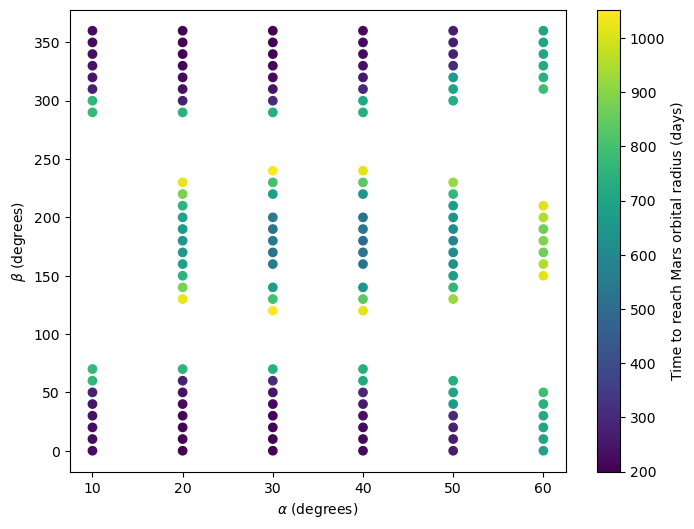

In [280]:
plt.figure(figsize=(8, 6))

plt.scatter(
    orientations_a,
    orientations_b,
    c=times
)

plt.colorbar(label="Time to reach Mars orbital radius (days)")
plt.xlabel(r"$\alpha$ (degrees)")
plt.ylabel(r"$\beta$ (degrees)")

In [287]:
min_time_id = np.argmin(successful[:,-1])

min_time_row = successful[min_time_id,:]

In [291]:
#Refine sail angle

alphas = np.arange(10, 31, 1)
beta = 0

fine_integration = []

for ai in alphas:
    orientation = [ai,0] #IN DEGREES
    physics.a_angle = ai * deg_to_rad
    physics.b_angle = bi * deg_to_rad

    orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
    orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5

    physics.position_vector = np.array(
            [physics.AU, 0.0, 0.0]
        )
    physics.velocity_vector = np.array([0, orbit_speed, 0])

    integration = physics.integrate_without_history(mars_orbit_radius, 3*orbital_period)
    fine_integration.append([integration, orientation])

    print(orientation)


[np.int64(10), 0]
[np.int64(11), 0]
[np.int64(12), 0]
[np.int64(13), 0]
[np.int64(14), 0]
[np.int64(15), 0]
[np.int64(16), 0]
[np.int64(17), 0]
[np.int64(18), 0]
[np.int64(19), 0]
[np.int64(20), 0]
[np.int64(21), 0]
[np.int64(22), 0]
[np.int64(23), 0]
[np.int64(24), 0]
[np.int64(25), 0]
[np.int64(26), 0]
[np.int64(27), 0]
[np.int64(28), 0]
[np.int64(29), 0]
[np.int64(30), 0]


In [292]:

import pickle

with open("fine_integration.pkl", "wb") as f:
    pickle.dump(fine_integration, f, protocol=pickle.HIGHEST_PROTOCOL)

"""
with open("fine_integration.pkl_", "rb") as f:
    integration_all = pickle.load(f)
"""

'\nwith open("fine_integration.pkl_", "rb") as f:\n    integration_all = pickle.load(f)\n'

In [293]:
false_count = 0
true_count = 0

fine_successful = []

for o in fine_integration:
    if o[0][-1] == True:
        time = o[0][-2]/(3600*24)
        a = o[-1][0]
        b = o[-1][1]
        fine_successful.append([a,b,time])

In [296]:
fine_successful = np.array(fine_successful)

In [297]:
min_time_id_fine = np.argmin(fine_successful[:,-1])

min_time_row_fine = fine_successful[min_time_id_fine,:]

In [373]:
print(min_time_row_fine)

[ 23.           0.         219.22453704]


(23,0) degrees seems to take us to mars' orbital radius the fastest at approximately 219 days.

In [299]:
print(fine_successful)

[[ 10.           0.         248.87731481]
 [ 11.           0.         242.36111111]
 [ 12.           0.         237.30324074]
 [ 13.           0.         233.26388889]
 [ 14.           0.         229.97685185]
 [ 15.           0.         227.30324074]
 [ 16.           0.         225.11574074]
 [ 17.           0.         223.34490741]
 [ 18.           0.         221.94444444]
 [ 19.           0.         220.85648148]
 [ 20.           0.         220.06944444]
 [ 21.           0.         219.54861111]
 [ 22.           0.         219.27083333]
 [ 23.           0.         219.22453704]
 [ 24.           0.         219.40972222]
 [ 25.           0.         219.81481481]
 [ 26.           0.         220.42824074]
 [ 27.           0.         221.26157407]
 [ 28.           0.         222.30324074]
 [ 29.           0.         223.55324074]
 [ 30.           0.         225.02314815]]


DT = 1000 is way too unstable, try DT=30. 

Orbital speed: 29788.8993205065
Initial state: [2.27994190e+11 0.00000000e+00 0.00000000e+00 0.00000000e+00
 2.74921053e+04 0.00000000e+00 0.00000000e+00]


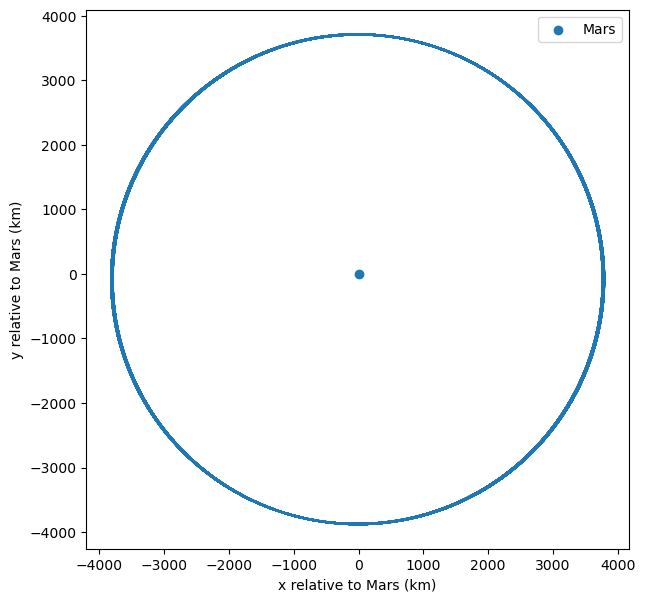

In [370]:
physics.DT = 50
physics.SAIL_AREA = 0 #2500
physics.MASS = 25

physics.a_angle = math.pi/6

orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
year =  365.25 * 24 * 60 * 60


physics.position_vector = np.array([physics.AU, 0.0, 0.0])
physics.velocity_vector = np.array([0, orbit_speed, 0])


r_rel = physics.MARS_RADIUS + 400e3
v_rel = np.sqrt(
    physics.GRAVITATIONAL * physics.MARS_MASS / r_rel
)

mars_start_phase = 0.0

physics.mars_position_vector = physics.update_mars_position(
    0.0,
    mars_start_phase
)

r_rel = physics.MARS_RADIUS + 400e3

v_rel = np.sqrt(
    physics.GRAVITATIONAL
    * physics.MARS_MASS
    / r_rel
)

physics.position_vector = (
    physics.mars_position_vector
    + np.array([r_rel, 0.0, 0.0])
)

mars_velocity_vector = physics.update_mars_velocity(
    0.0,
    mars_start_phase
)

physics.velocity_vector = (
    mars_velocity_vector
    + np.array([0.0, v_rel, 0.0])
)

state = np.concatenate((physics.position_vector, physics.velocity_vector, [0.0]))

print("Orbital speed:", orbit_speed)
print("Initial state:", state)

history_1000_mars = physics.stage_1(0, 100*mars_orbit_period, 0)

sc_history, mars_history, status = history_1000_mars

relative_positions = (
    sc_history[:, :3]
    - mars_history[:, :3]
)

plt.figure(figsize=(7,7))

plt.plot(
    relative_positions[:,0] / 1000,
    relative_positions[:,1] / 1000
)

plt.scatter(0, 0, label="Mars")

plt.xlabel("x relative to Mars (km)")
plt.ylabel("y relative to Mars (km)")
plt.axis("equal")
plt.legend()
plt.show()

In [365]:
print(history_1000_mars)

(array([[2.27353853e+11, 1.70754579e+10, 0.00000000e+00, ...,
        2.74921053e+04, 0.00000000e+00, 0.00000000e+00],
       [2.27353853e+11, 1.70782072e+10, 0.00000000e+00, ...,
        2.74920861e+04, 0.00000000e+00, 1.00000000e+02],
       [2.27353853e+11, 1.70809564e+10, 0.00000000e+00, ...,
        2.74920670e+04, 0.00000000e+00, 2.00000000e+02],
       ...,
       [2.26719913e+11, 3.64769407e+10, 0.00000000e+00, ...,
        2.72820086e+04, 0.00000000e+00, 7.08100000e+05],
       [2.26719735e+11, 3.64796689e+10, 0.00000000e+00, ...,
        2.72819686e+04, 0.00000000e+00, 7.08200000e+05],
       [2.26719556e+11, 3.64823971e+10, 0.00000000e+00, ...,
        2.72819286e+04, 0.00000000e+00, 7.08300000e+05]], shape=(7084, 7)), array([[2.27990400e+11, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [2.27990400e+11, 2.41302584e+06, 0.00000000e+00, 1.00000000e+02],
       [2.27990400e+11, 4.82605169e+06, 0.00000000e+00, 2.00000000e+02],
       ...,
       [2.27350425e+11, 1.707

Here, we find the optimal mars phase for stage 1 transfer.

In [392]:
physics.DT = 1000
physics.SAIL_AREA = 2500
physics.MASS = 25
physics.a_angle = 23 * math.pi / 180
physics.b_angle = 0

deg_to_rad = math.pi/180

mars_phase_partition = [10*i for i in range(0, 36)]
partition_trajectories = []

orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5


for phase in mars_phase_partition:
    phase_rad = phase * deg_to_rad
    
    physics.position_vector = np.array(
        [physics.AU, 0.0, 0.0]
    )
    physics.velocity_vector = np.array(
        [0, orbit_speed, 0]
    )

    integration = physics.stage_1_without_history(physics.MARS_HILL_RADIUS, orbital_period, phase_rad)

    partition_trajectories.append([integration, phase])

    print(phase)


0
10
20
30
40
50
60
70
80
90
100
110
120
130
140
150
160
170
180
190
200
210
220
230
240
250
260
270
280
290
300
310
320
330
340
350


In [393]:
import pickle

with open("partition_trajectories.pkl", "wb") as f:
    pickle.dump(partition_trajectories, f, protocol=pickle.HIGHEST_PROTOCOL)

"""
with open("partition_trajectories.pkl_", "rb") as f:
    integration_all = pickle.load(f)
"""

'\nwith open("partition_trajectories.pkl_", "rb") as f:\n    integration_all = pickle.load(f)\n'

In [407]:
with open("/Users/peytaguo/PHYS2201/Solar Sail Computational Project/partition_trajectories.pkl", "rb") as f:
    integration_all = pickle.load(f)

In [425]:
print(physics.MARS_HILL_RADIUS)

1084197898.154681


In [396]:
print(partition_trajectories)

[[(array([1.42804519e+11, 1.08463332e+11, 0.00000000e+00]), 17160000.0, 'overshot Mars'), 0], [(array([1.05241924e+11, 9.54847035e+10, 0.00000000e+00]), 17160000.0, 'overshot Mars'), 10], [(array([7.05037302e+10, 7.61805700e+10, 0.00000000e+00]), 17160000.0, 'overshot Mars'), 20], [(array([3.96454506e+10, 5.11375395e+10, 0.00000000e+00]), 17160000.0, 'overshot Mars'), 30], [(array([1.36048361e+10, 2.11163021e+10, 0.00000000e+00]), 17160000.0, 'overshot Mars'), 40], [(array([-6.82606893e+09, -1.29690335e+10,  0.00000000e+00]), 17160000.0, 'overshot Mars'), 50], [(array([-2.10301719e+10, -5.00850703e+10,  0.00000000e+00]), 17160000.0, 'overshot Mars'), 60], [(array([-2.85723288e+10, -8.91040549e+10,  0.00000000e+00]), 17160000.0, 'overshot Mars'), 70], [(array([-2.92241504e+10, -1.28839979e+11,  0.00000000e+00]), 17160000.0, 'overshot Mars'), 80], [(array([-2.29659375e+10, -1.68085428e+11,  0.00000000e+00]), 17160000.0, 'overshot Mars'), 90], [(array([-9.98787223e+09, -2.05647931e+11,  0

In [423]:
trajectories = []
for trajectory in partition_trajectories:
    print("{}: {}".format(trajectory[-1], np.linalg.norm(trajectory[-2][:-2]) - physics.MARS_HILL_RADIUS))
    #print(np.linalg.norm(trajectory[-2][:-2]))

40: 24035311999.98217
41: 20061180562.04727
42: 16085427969.125757
43: 12108350675.229902
44: 8130238079.25348
45: 4153523062.714369
46: 477530194.9067755
47: 1634502991.0102923
48: 5613181101.71509
49: 9591536303.329296


In [424]:
mars_phase_partition_fine = np.arange(40, 56, 1)

physics.DT = 1000
physics.SAIL_AREA = 2500
physics.MASS = 25
physics.a_angle = 23 * math.pi / 180
physics.b_angle = 0

deg_to_rad = math.pi/180

partition_trajectories_fine = []

orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5


for phase in mars_phase_partition_fine:
    phase_rad = phase * deg_to_rad
    
    physics.position_vector = np.array(
        [physics.AU, 0.0, 0.0]
    )
    physics.velocity_vector = np.array(
        [0, orbit_speed, 0]
    )

    integration = physics.stage_1_without_history(physics.MARS_HILL_RADIUS, orbital_period, phase_rad)

    partition_trajectories_fine.append([integration, phase])

    print(phase)

40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55


In [426]:
import pickle

with open("partition_trajectories_fine.pkl", "wb") as f:
    pickle.dump(partition_trajectories_fine, f, protocol=pickle.HIGHEST_PROTOCOL)

"""
with open("partition_trajectories.pkl_", "rb") as f:
    integration_all = pickle.load(f)
"""

'\nwith open("partition_trajectories.pkl_", "rb") as f:\n    integration_all = pickle.load(f)\n'

In [430]:
for trajectory in partition_trajectories_fine:
    print(trajectory[-1], np.linalg.norm(trajectory[0][:-2]) - physics.MARS_HILL_RADIUS)

40 24035311999.98217
41 20061180562.04727
42 16085427969.125757
43 12108350675.229902
44 8130238079.25348
45 4153523062.714369
46 173982835.77863598
47 1634502991.0102923
48 5613181101.71509
49 9591536303.329296
50 13571553451.785667
51 17548097611.330147
52 21523228928.404503
53 25496640337.94302
54 29468027571.53345
55 33437087588.692585


In [ ]:
mars_phase_partition_finer = np.arange(45, 47, 0.1)

physics.DT = 100
physics.SAIL_AREA = 2500
physics.MASS = 25
physics.a_angle = 23 * math.pi / 180
physics.b_angle = 0

deg_to_rad = math.pi/180

partition_trajectories_finer = []

orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5


for phase in mars_phase_partition_finer:
    phase_rad = phase * deg_to_rad
    
    physics.position_vector = np.array(
        [physics.AU, 0.0, 0.0]
    )
    physics.velocity_vector = np.array(
        [0, orbit_speed, 0]
    )

    integration = physics.stage_1_without_history(physics.MARS_HILL_RADIUS, orbital_period, phase_rad)

    partition_trajectories_finer.append([integration, phase])

    print(phase)

45.0
45.1
45.2
45.300000000000004
45.400000000000006
45.50000000000001
45.60000000000001
45.70000000000001
45.80000000000001
45.90000000000001
46.000000000000014
46.100000000000016
46.20000000000002
46.30000000000002
46.40000000000002
46.50000000000002
46.60000000000002
46.700000000000024
46.800000000000026
46.90000000000003
47.00000000000003
47.10000000000003
47.20000000000003


KeyboardInterrupt: 

In [ ]:
import pickle

with open("partition_trajectories_finer.pkl", "wb") as f:
    pickle.dump(partition_trajectories_finer, f, protocol=pickle.HIGHEST_PROTOCOL)

"""
with open("partition_trajectories.pkl_", "rb") as f:
    partition_trajectories_finer = pickle.load(f)
"""

'\nwith open("partition_trajectories.pkl_", "rb") as f:\n    integration_all = pickle.load(f)\n'

In [448]:
for trajectory in partition_trajectories_finer:
    print(round(trajectory[-1],1), 1, np.linalg.norm(trajectory[0][0][:3]) - physics.MARS_HILL_RADIUS)

    

45.0 1 4105170293.0114384
45.1 1 3707251691.9578533
45.2 1 3309326996.735882
45.3 1 2911396028.1131525
45.4 1 2513458451.7915697
45.5 1 2115513704.6837075
45.6 1 1717781145.5912611
45.7 1 1319819244.3229792
45.8 1 921845284.1686795
45.9 1 524076835.9890573
46.0 1 126062055.8724463
46.1 1 -68042.24048399925
46.2 1 -283725.81736302376
46.3 1 -214605.2688012123
46.4 1 -143160.57032227516
46.5 1 -30342.42734837532
46.6 1 90616712.23531723
46.7 1 488415385.58895826
46.8 1 886466865.5954931
46.9 1 1284309372.5171492
47.0 1 1682162615.5782926
47.1 1 2080250567.5017383
47.2 1 2478116163.2691135


In [4]:
import pickle 

with open("/Users/peytaguo/PHYS2201/Solar Sail Computational Project/partition_trajectories_finer.pkl", "rb") as f:
    partition_trajectories_finer = pickle.load(f)

In [ ]:
for t in partition_trajectories_finer:
    print(t)

[(array([2.61771094e+09, 4.48075124e+09, 0.00000000e+00]), 17159200.0, 'overshot Mars'), np.float64(45.0)]
[(array([2.41344536e+09, 4.13923552e+09, 0.00000000e+00]), 17159200.0, 'overshot Mars'), np.float64(45.1)]
[(array([2.20978068e+09, 3.79735834e+09, 0.00000000e+00]), 17159200.0, 'overshot Mars'), np.float64(45.2)]
[(array([2.00671842e+09, 3.45511968e+09, 0.00000000e+00]), 17159200.0, 'overshot Mars'), np.float64(45.300000000000004)]
[(array([1.80426039e+09, 3.11251918e+09, 0.00000000e+00]), 17159200.0, 'overshot Mars'), np.float64(45.400000000000006)]
[(array([1.60240882e+09, 2.76955598e+09, 0.00000000e+00]), 17159200.0, 'overshot Mars'), np.float64(45.50000000000001)]
[(array([1.40079620e+09, 2.42669664e+09, 0.00000000e+00]), 17159100.0, 'overshot Mars'), np.float64(45.60000000000001)]
[(array([1.20016353e+09, 2.08300406e+09, 0.00000000e+00]), 17159100.0, 'overshot Mars'), np.float64(45.70000000000001)]
[(array([1.00014979e+09, 1.73893923e+09, 0.00000000e+00]), 17159100.0, 'overs

Set the phase to an angle between 46.2 to 46.5 degrees. 

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import math

%load_ext autoreload
%autoreload 2

import steering_rule
import physics

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [32]:
mars_start_phase = 46.2*math.pi/180
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5
orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
a_angle = 23*math.pi/180
b_angle = 0
safe_dist = 200e3
target_dist = 400e3

position = np.array([
    physics.AU, 0.0, 0.0
])

vel = np.array([
    0, orbit_speed, 0
])

integrate = steering_rule.to_mars_integrator(
    physics.MARS_HILL_RADIUS,
    2*orbital_period, 
    mars_start_phase, 
    position, 
    vel, 
    a_angle,
    b_angle,
    safe_dist,
    target_dist
)

[-1.96049506e+11  1.14853202e+11  0.00000000e+00] [-16151.71753236 -15977.74388872      0.        ] [-1.96337609e+11  1.15892906e+11  0.00000000e+00] 17026000.0 stage 1 success
energy: 1.904e+07 J/kg, angle: (45.0°, 180.0°), osc. periapsis alt.: 425947.7 km, dist from mars: 1078882.3 km, to time limit: 0.2698
energy: 1.904e+07 J/kg, angle: (45.0°, 180.0°), osc. periapsis alt.: 425942.0 km, dist from mars: 1076050.2 km, to time limit: 0.2698
energy: 1.904e+07 J/kg, angle: (45.0°, 180.0°), osc. periapsis alt.: 425936.2 km, dist from mars: 1073219.4 km, to time limit: 0.2698
energy: 1.904e+07 J/kg, angle: (45.0°, 180.0°), osc. periapsis alt.: 425930.5 km, dist from mars: 1070390.0 km, to time limit: 0.2698
energy: 1.904e+07 J/kg, angle: (45.0°, 180.0°), osc. periapsis alt.: 425924.9 km, dist from mars: 1067562.1 km, to time limit: 0.2698
energy: 1.904e+07 J/kg, angle: (45.0°, 180.0°), osc. periapsis alt.: 425919.2 km, dist from mars: 1064735.5 km, to time limit: 0.2698
energy: 1.904e+07 J

KeyboardInterrupt: 

Need to find a better sail orientation for stage 1. The relative velocity between space craft and mars is quite large, it is hard for the spacecraft to reach a bound orbit around Mars. 

In [45]:
import pickle 

with open("/Users/peytaguo/PHYS2201/Solar Sail Computational Project/integration_all_v2.pkl", "rb") as f:
    integration_all_v2 = pickle.load(f)

successful = []

for o in integration_all_v2:
    if o[0][-1] == True:
        time = o[0][-2]/(3600*24)
        a = o[-1][0]
        b = o[-1][1]
        successful.append([a,b,time])

successful = np.array(successful)


orientations_a = successful[:,0]
orientations_b = successful[:,1]
times = successful[:,-1]

In [46]:
successful_orientations =list(zip(orientations_a, orientations_b))

ideal_orientations = []

for a, b in successful_orientations:
    if b == 0:
        ideal_orientations.append((a,b))

for i in ideal_orientations:
    print(i)


(np.float64(10.0), np.float64(0.0))
(np.float64(20.0), np.float64(0.0))
(np.float64(30.0), np.float64(0.0))
(np.float64(40.0), np.float64(0.0))
(np.float64(50.0), np.float64(0.0))
(np.float64(60.0), np.float64(0.0))


In [50]:
mars_start_phase = 46.2*math.pi/180
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5
orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
a_angle = 23*math.pi/180
b_angle = 0
safe_dist = 200e3
target_dist = 400e3

position = np.array([
    physics.AU, 0.0, 0.0
])

vel = np.array([
    0, orbit_speed, 0
])

data_list = []

for a,b in ideal_orientations:
    data = steering_rule.stage_1_modified(
        position, vel, a, b, 3*orbital_period
    )
    print(data)
    data_list.append(data)

((np.float64(10.0), np.float64(0.0)), np.float64(4871.342818779933), 225.3587962962963, 'successful')
((np.float64(20.0), np.float64(0.0)), np.float64(6090.708528693085), 200.19675925925927, 'successful')
((np.float64(29.999999999999996), np.float64(0.0)), np.float64(6299.042206972172), 201.07638888888889, 'successful')
((np.float64(40.0), np.float64(0.0)), np.float64(5632.512851099977), 219.49074074074073, 'successful')
((np.float64(50.0), np.float64(0.0)), np.float64(3884.2209364766363), 268.63425925925924, 'successful')
((np.float64(59.99999999999999), np.float64(0.0)), np.float64(2301.676966682834), 694.7569444444445, 'successful')


Try alpha = 60 degrees 

In [52]:
mars_phase_partition = [10*i for i in range(36)]

physics.DT = 1000
physics.SAIL_AREA = 2500
physics.MASS = 25
physics.a_angle = np.deg2rad(60)
physics.b_angle = 0

deg_to_rad = np.pi / 180

orbit_speed = np.sqrt(
    physics.GRAVITATIONAL
    * physics.SUN_MASS
    / physics.AU
)

orbital_period = 2 * np.pi * (
    physics.AU**3 /
    (physics.GRAVITATIONAL * physics.SUN_MASS)
)**0.5

max_time = 2 * orbital_period

partition_trajectories = []

for phase in mars_phase_partition:

    phase_rad = phase * deg_to_rad

    physics.position_vector = np.array(
        [physics.AU, 0.0, 0.0]
    )

    physics.velocity_vector = np.array(
        [0.0, orbit_speed, 0.0]
    )

    integration = physics.stage_1_without_history(
        physics.MARS_HILL_RADIUS,
        max_time,
        phase_rad
    )

    partition_trajectories.append([
        integration,
        phase
    ])

    print(phase)

0
10
20
30
40
50
60
70
80
90
100
110
120
130
140
150
160
170
180
190
200
210
220
230
240
250
260
270
280
290
300
310
320
330
340
350


In [53]:
import pickle 

with open("60_phase_coarse.pkl", "wb") as f:
    pickle.dump(partition_trajectories, f, protocol=pickle.HIGHEST_PROTOCOL)

In [63]:
analyse = []
angles = []
for trajectory in partition_trajectories:
    angles.append(round(trajectory[-1],1))
    print(round(trajectory[-1],1), np.linalg.norm(trajectory[0][0][:3]) - physics.MARS_HILL_RADIUS)
    analyse.append(np.linalg.norm(trajectory[0][0][:3]) - physics.MARS_HILL_RADIUS)

print(angles[analyse.index(min(analyse))])

0 352570652737.7392
10 326138859326.9915
20 297216591011.0725
30 266024296809.72714
40 232799605340.97888
50 197796946343.20123
60 161281661623.78885
70 123533615177.84991
80 84833133086.86385
90 45300548213.260765
100 5690799036.084678
110 31864443101.362083
120 71370628370.63742
130 110328952843.31169
140 148440521201.8168
150 185414688115.5564
160 220969797965.76028
170 254835130134.6191
180 286752882249.2338
190 316480102332.83044
200 343790524653.21075
210 368476285367.3622
220 390349501180.55786
230 409243697451.09827
240 425015074172.8704
250 437543599869.7956
260 446733924927.7767
270 452516107366.64716
280 454846145562.4797
290 453706313992.8282
300 449105299706.7719
310 441078138920.18567
320 429685954712.0422
330 415015496933.1157
340 397178477330.6255
350 376310657355.22327
100


In [67]:
mars_phase_partition = [x for x in range(95, 105)]

physics.DT = 1000
physics.SAIL_AREA = 2500
physics.MASS = 25
physics.a_angle = np.deg2rad(60)
physics.b_angle = 0

deg_to_rad = np.pi / 180

orbit_speed = np.sqrt(
    physics.GRAVITATIONAL
    * physics.SUN_MASS
    / physics.AU
)

orbital_period = 2 * np.pi * (
    physics.AU**3 /
    (physics.GRAVITATIONAL * physics.SUN_MASS)
)**0.5

max_time = 2 * orbital_period

partition_trajectories = []

for phase in mars_phase_partition:

    phase_rad = phase * deg_to_rad

    physics.position_vector = np.array(
        [physics.AU, 0.0, 0.0]
    )

    physics.velocity_vector = np.array(
        [0.0, orbit_speed, 0.0]
    )

    integration = physics.stage_1_without_history(
        physics.MARS_HILL_RADIUS,
        max_time,
        phase_rad
    )

    partition_trajectories.append([
        integration,
        phase
    ])

    print(phase)

95
96
97
98
99
100
101
102
103
104


In [69]:
analyse = []
angles = []
for trajectory in partition_trajectories:
    angles.append(round(trajectory[-1],1))
    print(round(trajectory[-1],1), np.linalg.norm(trajectory[0][0][:3]) - physics.MARS_HILL_RADIUS)
    analyse.append(np.linalg.norm(trajectory[0][0][:3]) - physics.MARS_HILL_RADIUS)

print(angles[analyse.index(min(analyse))])

95 25530190288.2844
96 21567361221.832554
97 17601523312.549477
98 13633141710.519487
99 9662717931.02285
100 5690799036.084678
101 1717492480.1875603
102 72112449.52112556
103 4049479415.9081793
104 8026098631.508033
102


In [71]:
mars_phase_partition = [x/10 for x in range(1011, 1030)]
print(mars_phase_partition)

[101.1, 101.2, 101.3, 101.4, 101.5, 101.6, 101.7, 101.8, 101.9, 102.0, 102.1, 102.2, 102.3, 102.4, 102.5, 102.6, 102.7, 102.8, 102.9]


In [72]:
mars_phase_partition = [x/10 for x in range(1011, 1030)]

physics.DT = 100
physics.SAIL_AREA = 2500
physics.MASS = 25
physics.a_angle = np.deg2rad(60)
physics.b_angle = 0

deg_to_rad = np.pi / 180

orbit_speed = np.sqrt(
    physics.GRAVITATIONAL
    * physics.SUN_MASS
    / physics.AU
)

orbital_period = 2 * np.pi * (
    physics.AU**3 /
    (physics.GRAVITATIONAL * physics.SUN_MASS)
)**0.5

max_time = 2 * orbital_period

partition_trajectories = []

for phase in mars_phase_partition:

    phase_rad = phase * deg_to_rad

    physics.position_vector = np.array(
        [physics.AU, 0.0, 0.0]
    )

    physics.velocity_vector = np.array(
        [0.0, orbit_speed, 0.0]
    )

    integration = physics.stage_1_without_history(
        physics.MARS_HILL_RADIUS,
        max_time,
        phase_rad
    )

    partition_trajectories.append([
        integration,
        phase
    ])

    print(phase)

101.1
101.2
101.3
101.4
101.5
101.6
101.7
101.8
101.9
102.0
102.1
102.2
102.3
102.4
102.5
102.6
102.7
102.8
102.9


In [73]:
import pickle 

with open("60_phase_fine.pkl", "wb") as f:
    pickle.dump(partition_trajectories, f, protocol=pickle.HIGHEST_PROTOCOL)

In [74]:
for i in partition_trajectories:
    print(i)

[(array([2.30635261e+09, 6.29278941e+08, 0.00000000e+00]), 60002700.0, 'overshot Mars'), 101.1]
[(array([1.92262738e+09, 5.26165466e+08, 0.00000000e+00]), 60002300.0, 'overshot Mars'), 101.2]
[(array([1.53901868e+09, 4.22540752e+08, 0.00000000e+00]), 60001700.0, 'overshot Mars'), 101.3]
[(array([1.15559466e+09, 3.18274714e+08, 0.00000000e+00]), 60000900.0, 'overshot Mars'), 101.4]
[(array([4.35251430e+08, 9.92967611e+08, 0.00000000e+00]), 59617600.0, 'Stage 1 success'), 101.5]
[(array([-2.75531959e+07,  1.08380813e+09,  0.00000000e+00]), 59530500.0, 'Stage 1 success'), 101.6]
[(array([-4.15765078e+08,  1.00122410e+09,  0.00000000e+00]), 59529000.0, 'Stage 1 success'), 101.7]
[(array([-7.47710826e+08,  7.84837957e+08,  0.00000000e+00]), 59589800.0, 'Stage 1 success'), 101.8]
[(array([-1.00820804e+09,  3.98532833e+08,  0.00000000e+00]), 59725900.0, 'Stage 1 success'), 101.9]
[(array([-1.12630043e+09, -3.17327390e+08,  0.00000000e+00]), 60004600.0, 'overshot Mars'), 102.0]
[(array([-1.508

In [87]:
mars_phase_partition = np.arange(101.5, 102.0, 0.01)

physics.DT = 1000
physics.SAIL_AREA = 2500
physics.MASS = 25
physics.a_angle = np.deg2rad(60)
physics.b_angle = 0

deg_to_rad = np.pi / 180

orbit_speed = np.sqrt(
    physics.GRAVITATIONAL
    * physics.SUN_MASS
    / physics.AU
)

orbital_period = 2 * np.pi * (
    physics.AU**3 /
    (physics.GRAVITATIONAL * physics.SUN_MASS)
)**0.5

max_time = 2 * orbital_period

partition_trajectories = []

for phase in mars_phase_partition:

    phase_rad = phase * deg_to_rad

    physics.position_vector = np.array(
        [physics.AU, 0.0, 0.0]
    )

    physics.velocity_vector = np.array(
        [0.0, orbit_speed, 0.0]
    )

    integration = physics.stage_1_without_history(
        physics.MARS_HILL_RADIUS,
        max_time,
        phase_rad
    )

    partition_trajectories.append([
        integration,
        phase
    ])

    print(phase)


periapsis: 800678.5 km, m_energy: 2.403e+06 J/kg, rel_speed: 2.210 km/s, rel_pos: [-4.52126837e+08 -9.85280946e+08  0.00000000e+00], t: 690.19 days
101.5
periapsis: 761060.9 km, m_energy: 2.410e+06 J/kg, rel_speed: 2.213 km/s, rel_pos: [-4.00379093e+08 -1.00676278e+09  0.00000000e+00], t: 690.01 days
101.51
periapsis: 721457.2 km, m_energy: 2.418e+06 J/kg, rel_speed: 2.217 km/s, rel_pos: [-3.50367014e+08 -1.02429272e+09  0.00000000e+00], t: 689.86 days
101.52000000000001
periapsis: 681852.1 km, m_energy: 2.426e+06 J/kg, rel_speed: 2.220 km/s, rel_pos: [-3.01214151e+08 -1.03988615e+09  0.00000000e+00], t: 689.72 days
101.53000000000002
periapsis: 642248.4 km, m_energy: 2.434e+06 J/kg, rel_speed: 2.224 km/s, rel_pos: [-2.52921871e+08 -1.05353152e+09  0.00000000e+00], t: 689.59 days
101.54000000000002
periapsis: 602673.0 km, m_energy: 2.442e+06 J/kg, rel_speed: 2.228 km/s, rel_pos: [-2.06372045e+08 -1.06317223e+09  0.00000000e+00], t: 689.49 days
101.55000000000003
periapsis: 563106.7 km,

In [ ]:
mars_phase_partition = np.arange( 101.69, 101.711, 0.001)


physics.DT = 1000
physics.SAIL_AREA = 2500
physics.MASS = 25
physics.a_angle = np.deg2rad(60)
physics.b_angle = 0

deg_to_rad = np.pi / 180

orbit_speed = np.sqrt(
    physics.GRAVITATIONAL
    * physics.SUN_MASS
    / physics.AU
)

orbital_period = 2 * np.pi * (
    physics.AU**3 /
    (physics.GRAVITATIONAL * physics.SUN_MASS)
)**0.5

max_time = 2 * orbital_period

partition_trajectories = []

for phase in mars_phase_partition:

    phase_rad = phase * deg_to_rad

    physics.position_vector = np.array(
        [physics.AU, 0.0, 0.0]
    )

    physics.velocity_vector = np.array(
        [0.0, orbit_speed, 0.0]
    )

    integration = physics.stage_1_without_history(
        physics.MARS_HILL_RADIUS,
        max_time,
        phase_rad
    )

    partition_trajectories.append([
        integration,
        phase
    ])

    print(phase)


periapsis: 50400.6 km, m_energy: 2.568e+06 J/kg, rel_speed: 2.284 km/s, rel_pos: [ 3.67692405e+08 -1.01856761e+09  0.00000000e+00], t: 689.06 days
101.69
periapsis: 46493.4 km, m_energy: 2.569e+06 J/kg, rel_speed: 2.284 km/s, rel_pos: [ 3.71561495e+08 -1.01770703e+09  0.00000000e+00], t: 689.06 days
101.691
periapsis: 42591.7 km, m_energy: 2.570e+06 J/kg, rel_speed: 2.284 km/s, rel_pos: [ 3.75430609e+08 -1.01684642e+09  0.00000000e+00], t: 689.06 days
101.69200000000001
periapsis: 38727.5 km, m_energy: 2.571e+06 J/kg, rel_speed: 2.285 km/s, rel_pos: [ 3.78404284e+08 -1.01388513e+09  0.00000000e+00], t: 689.07 days
101.69300000000001
periapsis: 34840.8 km, m_energy: 2.572e+06 J/kg, rel_speed: 2.285 km/s, rel_pos: [ 3.82273330e+08 -1.01302406e+09  0.00000000e+00], t: 689.07 days
101.69400000000002
periapsis: 30964.7 km, m_energy: 2.572e+06 J/kg, rel_speed: 2.286 km/s, rel_pos: [ 3.86142401e+08 -1.01216296e+09  0.00000000e+00], t: 689.07 days
101.69500000000002
periapsis: 27102.5 km, m_en

Try phase: 101.708 deg

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import math

from scipy.integrate import solve_ivp

%load_ext autoreload
%autoreload 2

import steering_rule
import physics

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [107]:
mars_start_phase = 101.708*math.pi/180
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5
orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
a_angle = 60*math.pi/180
b_angle = 0
safe_dist = 200e3
target_dist = 400e3

position = np.array([
    physics.AU, 0.0, 0.0
])

vel = np.array([
    0, orbit_speed, 0
])

integrate = steering_rule.to_mars_integrator(
    physics.MARS_HILL_RADIUS,
    5*orbital_period, 
    mars_start_phase, 
    position, 
    vel, 
    a_angle,
    b_angle,
    safe_dist,
    target_dist,
    dt1=1000
)

[-4.99458263e+10  2.21362158e+11  0.00000000e+00] [-24431.64286543  -3224.13247017      0.        ] [-5.03786792e+10  2.22354697e+11  0.00000000e+00] 59540000.0 stage 1 success
alpha=45.0, beta=180.0, E=5.119484e+06, hp=1515810.6 km
alpha=60.0, beta=180.0, E=3.473165e+06, hp=1593313.1 km
alpha=75.0, beta=180.0, E=2.447494e+06, hp=1263992.5 km
alpha=85.0, beta=180.0, E=2.205162e+06, hp=809974.2 km
alpha=90.0, beta=180.0, E=2.173484e+06, hp=695462.5 km
energy: 2.585e+06 J/kg, angle: (90.0°, 180.0°), osc. periapsis alt.: 813.5 km, dist from mars: 1082818.2 km, to time limit: 0.3774
alpha=45.0, beta=180.0, E=5.117262e+06, hp=1518051.9 km
alpha=60.0, beta=180.0, E=3.471180e+06, hp=1594852.1 km
alpha=75.0, beta=180.0, E=2.446697e+06, hp=1264137.8 km
alpha=85.0, beta=180.0, E=2.205048e+06, hp=810179.8 km
alpha=90.0, beta=180.0, E=2.173446e+06, hp=695778.3 km
energy: 2.585e+06 J/kg, angle: (90.0°, 180.0°), osc. periapsis alt.: 812.3 km, dist from mars: 1081672.7 km, to time limit: 0.3774
alpha

KeyboardInterrupt: 

In [118]:
alpha_values = np.arange(56.56, 56.60, 0.005)

results = []

start_pos = np.array([physics.AU, 0.0, 0.0])

orbit_speed = np.sqrt(
    physics.GRAVITATIONAL
    * physics.SUN_MASS
    / physics.AU
)

start_vel = np.array([0.0, orbit_speed, 0.0])

orbital_period = 2 * np.pi * (
    physics.AU**3 /
    (physics.GRAVITATIONAL * physics.SUN_MASS)
)**0.5

for alpha in alpha_values:

    result = steering_rule.stage_1_modified(
        start_pos,
        start_vel,
        alpha,
        0,                  # beta = 0
        3 * orbital_period,
        dt=250
    )

    print(result)

    if result[-1] == "successful":
        orientation, rel_speed, time_days, status = result

        results.append([
            alpha,
            rel_speed,
            time_days
        ])


((np.float64(56.56), 0.0), np.float64(1003.9557281435341), 419.95949074074076, 'successful')
((np.float64(56.56500000000001), 0.0), np.float64(990.5390727025573), 421.56539351851853, 'successful')
((np.float64(56.57000000000001), 0.0), np.float64(975.4176669613742), 423.41435185185185, 'successful')
((np.float64(56.57500000000001), 0.0), np.float64(957.5780528904004), 425.6510416666667, 'successful')
((np.float64(56.58000000000001), 0.0), np.float64(934.2422396401641), 428.671875, 'successful')
((np.float64(56.585000000000015), 0.0), np.float64(1077.7221477518497), 636.7332175925926, 'successful')
((np.float64(56.59000000000002), 0.0), np.float64(1081.4786175093457), 636.9241898148148, 'successful')
((np.float64(56.59500000000002), 0.0), np.float64(1085.1955550850685), 637.1122685185185, 'successful')


In [126]:
physics.DT = 250
physics.SAIL_AREA = 2500
physics.MASS = 25

deg_to_rad = np.pi / 180
physics.a_angle = 56.58*deg_to_rad
physics.b_angle = 0


mars_phase_partition = np.arange(
    73.46,
    73.58,
    0.005
)

orbit_speed = np.sqrt(
    physics.GRAVITATIONAL
    * physics.SUN_MASS
    / physics.AU
)

orbital_period = 2 * np.pi * (
    physics.AU**3 /
    (physics.GRAVITATIONAL * physics.SUN_MASS)
)**0.5

max_time = 2 * orbital_period

partition_trajectories = []

for phase in mars_phase_partition:

    phase_rad = phase * deg_to_rad

    physics.position_vector = np.array(
        [physics.AU, 0.0, 0.0]
    )

    physics.velocity_vector = np.array(
        [0.0, orbit_speed, 0.0]
    )

    integration = physics.stage_1_without_history(
        physics.MARS_HILL_RADIUS,
        max_time,
        phase_rad
    )

    partition_trajectories.append([
        integration,
        phase
    ])

    print(phase)

73.46
periapsis: 23146.0 km, m_energy: 4.320e+05 J/kg, rel_speed: 0.971 km/s, rel_pos: [9.57316219e+08 5.08939579e+08 0.00000000e+00], t: 428.18 days
73.46499999999999
periapsis: 21840.3 km, m_energy: 4.333e+05 J/kg, rel_speed: 0.972 km/s, rel_pos: [9.57669893e+08 5.08011209e+08 0.00000000e+00], t: 427.93 days
73.46999999999998
periapsis: 20596.1 km, m_energy: 4.347e+05 J/kg, rel_speed: 0.974 km/s, rel_pos: [9.58025987e+08 5.07145305e+08 0.00000000e+00], t: 427.69 days
73.47499999999998
periapsis: 19427.7 km, m_energy: 4.360e+05 J/kg, rel_speed: 0.975 km/s, rel_pos: [9.58605289e+08 5.06445578e+08 0.00000000e+00], t: 427.45 days
73.47999999999998
periapsis: 18303.2 km, m_energy: 4.374e+05 J/kg, rel_speed: 0.977 km/s, rel_pos: [9.58966845e+08 5.05704947e+08 0.00000000e+00], t: 427.20 days
73.48499999999997
periapsis: 17236.8 km, m_energy: 4.388e+05 J/kg, rel_speed: 0.978 km/s, rel_pos: [9.59331197e+08 5.05026830e+08 0.00000000e+00], t: 426.96 days
73.48999999999997
periapsis: 16227.6 km,

In [127]:
physics.DT = 250
physics.SAIL_AREA = 2500
physics.MASS = 25

deg_to_rad = np.pi / 180
physics.a_angle = 56.58*deg_to_rad
physics.b_angle = 0


mars_phase_partition = np.arange(
    73.58,
    74.58,
    0.005
)

orbit_speed = np.sqrt(
    physics.GRAVITATIONAL
    * physics.SUN_MASS
    / physics.AU
)

orbital_period = 2 * np.pi * (
    physics.AU**3 /
    (physics.GRAVITATIONAL * physics.SUN_MASS)
)**0.5

max_time = 2 * orbital_period

partition_trajectories = []

for phase in mars_phase_partition:

    phase_rad = phase * deg_to_rad

    physics.position_vector = np.array(
        [physics.AU, 0.0, 0.0]
    )

    physics.velocity_vector = np.array(
        [0.0, orbit_speed, 0.0]
    )

    integration = physics.stage_1_without_history(
        physics.MARS_HILL_RADIUS,
        max_time,
        phase_rad
    )

    partition_trajectories.append([
        integration,
        phase
    ])

    print(phase)

periapsis: 6251.2 km, m_energy: 4.634e+05 J/kg, rel_speed: 1.003 km/s, rel_pos: [9.61319670e+08 5.01010688e+08 0.00000000e+00], t: 422.65 days
73.58
periapsis: 6024.5 km, m_energy: 4.648e+05 J/kg, rel_speed: 1.004 km/s, rel_pos: [9.61303114e+08 5.01297338e+08 0.00000000e+00], t: 422.41 days
73.585
periapsis: 5820.4 km, m_energy: 4.662e+05 J/kg, rel_speed: 1.006 km/s, rel_pos: [9.61064795e+08 5.01535537e+08 0.00000000e+00], t: 422.18 days
73.58999999999999
periapsis: 5649.7 km, m_energy: 4.676e+05 J/kg, rel_speed: 1.007 km/s, rel_pos: [9.60830347e+08 5.01834899e+08 0.00000000e+00], t: 421.94 days
73.59499999999998
periapsis: 5511.8 km, m_energy: 4.690e+05 J/kg, rel_speed: 1.008 km/s, rel_pos: [9.60599885e+08 5.02195448e+08 0.00000000e+00], t: 421.71 days
73.59999999999998
periapsis: 5406.2 km, m_energy: 4.704e+05 J/kg, rel_speed: 1.010 km/s, rel_pos: [9.60373526e+08 5.02617207e+08 0.00000000e+00], t: 421.48 days
73.60499999999998
periapsis: 5332.5 km, m_energy: 4.718e+05 J/kg, rel_speed

KeyboardInterrupt: 

In [ ]:
mars_start_phase = 73.605*math.pi/180
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5
orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
a_angle = 56.58*math.pi/180
b_angle = 0
safe_dist = 200e3
target_dist = 400e3

position = np.array([
    physics.AU, 0.0, 0.0
])

vel = np.array([
    0, orbit_speed, 0
])

integrate = steering_rule.to_mars_integrator(
    physics.MARS_HILL_RADIUS,
    1.18*orbital_period, 
    mars_start_phase, 
    position, 
    vel, 
    a_angle,
    b_angle,
    safe_dist,
    dt1=250
)

[ 9.52641243e+10 -2.07070081e+11  0.00000000e+00] [21062.56371367  9536.40661483     0.        ] [ 9.43037508e+10 -2.07572698e+11  0.00000000e+00] 36415500.0 stage 1 success
minimise future o_energy
energy: 4.704e+05 J/kg, angle: (40.0°, 0.0°), osc. periapsis alt.: 5406.2 km, dist from mars: 1083947.1 km, to time limit: 0.9780
minimise future o_energy
energy: 4.702e+05 J/kg, angle: (40.0°, 0.0°), osc. periapsis alt.: 5194.3 km, dist from mars: 1081928.3 km, to time limit: 0.9781
minimise future o_energy
energy: 4.700e+05 J/kg, angle: (40.0°, 0.0°), osc. periapsis alt.: 4984.7 km, dist from mars: 1079909.7 km, to time limit: 0.9781
minimise future o_energy
energy: 4.697e+05 J/kg, angle: (40.0°, 0.0°), osc. periapsis alt.: 4777.6 km, dist from mars: 1077891.4 km, to time limit: 0.9782
minimise future o_energy
energy: 4.695e+05 J/kg, angle: (40.0°, 0.0°), osc. periapsis alt.: 4572.8 km, dist from mars: 1075873.3 km, to time limit: 0.9782
minimise future o_energy
energy: 4.693e+05 J/kg, an

In [158]:
import pickle 

with open("integrate_final.pkl", "wb") as f:
    pickle.dump(integrate, f, protocol=pickle.HIGHEST_PROTOCOL)

In [166]:
history_trajectory = integrate[0]
steering_histroy = integrate[1]

In [170]:
history_trajectory = np.array(history_trajectory)
t = history_trajectory[::,-1]
x = history_trajectory[::,0]
y = history_trajectory[::,1]

In [176]:
mars_traj = []
for time in t: 
    mars_traj.append(steering_rule.update_mars_position(time, 73.605*math.pi/180))

mars_traj = np.array(mars_traj)
mars_x = mars_traj[::, 0]
mars_y = mars_traj[::, 1]

In [177]:
print(mars_traj[0])

[6.43520550e+10 2.18719993e+11 0.00000000e+00]


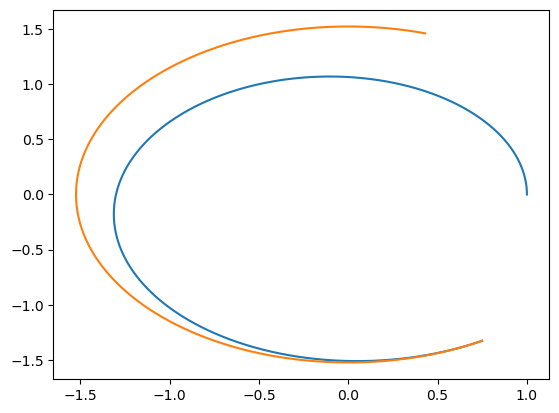

In [179]:
plt.plot(
    x/steering_rule.AU,
    y/steering_rule.AU)
plt.plot(
    mars_x/steering_rule.AU,
    mars_y/steering_rule.AU)
plt.show()

In [25]:
mars_start_phase = 73.605*math.pi/180
orbital_period = 2 * math.pi * ( (physics.AU) ** 3 / (physics.GRAVITATIONAL * physics.SUN_MASS) )**0.5
orbit_speed = math.sqrt(physics.GRAVITATIONAL * physics.SUN_MASS / physics.AU)
a_angle = 56.6*math.pi/180
b_angle = 0
safe_dist = 200e3
target_dist = 400e3

position = np.array([
    physics.AU, 0.0, 0.0
])

vel = np.array([
    0, orbit_speed, 0
])

integrate_2 = steering_rule.to_mars_integrator(
    physics.MARS_HILL_RADIUS,
    1.18*orbital_period, 
    mars_start_phase, 
    position, 
    vel, 
    a_angle,
    b_angle,
    safe_dist,
    dt1=250
)

[ 1.02402117e+11 -2.03582399e+11  0.00000000e+00] [20722.99582661 10316.2833328      0.        ] [ 1.01483818e+11 -2.04158412e+11  0.00000000e+00] 36745000.0 stage 1 success
minimise future o_energy
energy: 4.422e+05 J/kg, angle: (35.0°, 0.0°), osc. periapsis alt.: 84428.1 km, dist from mars: 1084003.0 km, to time limit: 0.9869
minimise future o_energy
energy: 4.420e+05 J/kg, angle: (35.0°, 0.0°), osc. periapsis alt.: 83985.5 km, dist from mars: 1082052.6 km, to time limit: 0.9869
minimise future o_energy
energy: 4.417e+05 J/kg, angle: (35.0°, 0.0°), osc. periapsis alt.: 83543.8 km, dist from mars: 1080102.4 km, to time limit: 0.9870
minimise future o_energy
energy: 4.415e+05 J/kg, angle: (35.0°, 0.0°), osc. periapsis alt.: 83102.8 km, dist from mars: 1078152.5 km, to time limit: 0.9870
minimise future o_energy
energy: 4.413e+05 J/kg, angle: (35.0°, 0.0°), osc. periapsis alt.: 82662.7 km, dist from mars: 1076202.9 km, to time limit: 0.9871
minimise future o_energy
energy: 4.411e+05 J/k

7


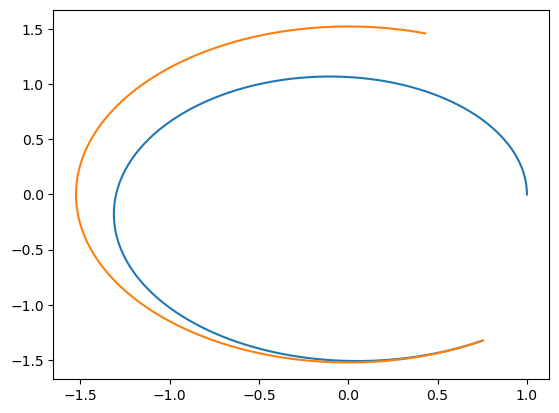

In [28]:
print(len(integrate_2))


history_trajectory_2 = np.array(integrate_2[0])
t = history_trajectory_2[::,-1]
x = history_trajectory_2[::,0]
y = history_trajectory_2[::,1]

mars_traj = []
for time in t: 
    mars_traj.append(steering_rule.update_mars_position(time, 73.605*math.pi/180))

mars_traj = np.array(mars_traj)
mars_x = mars_traj[::, 0]
mars_y = mars_traj[::, 1]

plt.plot(
    x/steering_rule.AU,
    y/steering_rule.AU)
plt.plot(
    mars_x/steering_rule.AU,
    mars_y/steering_rule.AU)
plt.show()